The `isharah_exploration.ipynb` notebook documents dataset exploration and preprocessing experiments. It is not intended to be executed end-to-end using **Run All**.

In [3]:
import sys
from collections import Counter
from pathlib import Path
from subprocess import run
from time import perf_counter

import matplotlib.pyplot as plt
import mediapipe as mp
import numpy as np
import pandas as pd
from PIL import Image, UnidentifiedImageError

project = Path.cwd().parent
source_directory = project / "src"

if str(source_directory) not in sys.path:
    sys.path.insert(0, str(source_directory))

from keypoint_validation import is_valid_keypoint_file

In [ ]:
project = Path.cwd()
if project.name == "notebooks":
    project = project.parent
folder = project / "data" / "raw" / "isharah500" / "annotations" / "SI"
print("Current directory:", Path.cwd())
print("Annotations folder exists:", folder.exists())
for name in ["train.txt", "dev.txt", "test.txt"]:
    path = folder / name
    if path.exists():
        lines = path.read_text(encoding="utf-8-sig").splitlines()
        print("\nFile:", name)
        print("Number of lines:", len(lines))
        print("First line:", lines[0] if lines else "EMPTY")
    else:
        print("\nFile not found:", path)

Current directory: e:\DEPI Project\SIGNOVA_ESL\notebooks
Annotations folder exists: True

File: train.txt
Number of lines: 5001
First line: id|gloss|text

File: dev.txt
Number of lines: 501
First line: id|gloss|text

File: test.txt
Number of lines: 2001
First line: id|gloss|text


In [ ]:

import pandas as pd
SPLIT_NAMES = ("train", "dev", "test")
def load_annotations(directory, split_name):
    file_path = directory / f"{split_name}.txt"
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing annotation file: {file_path}")
    return pd.read_csv(file_path, sep="|")
datasets = {
    split_name: load_annotations(folder, split_name)
    for split_name in SPLIT_NAMES
}
for split_name, dataset in datasets.items():
    print(f"{split_name}: {dataset.shape}")
display(datasets["train"].head())

train: (5000, 3)
dev: (500, 3)
test: (2000, 3)


,id,gloss,text
0,00_0001,سوال هو,من هو
1,00_0002,هو معلم لغه اشاره,هو مدرس لغه اشاره
2,00_0003,استفهام هو معلم هو,هل انت مدرس
3,00_0004,هو معلم لا انا مدرسه,انت لست مدرس انا طالب
4,00_0005,هو سوال,هو من


In [ ]:

REQUIRED_COLUMNS = {"id", "gloss", "text"}
def check_data_quality(dataset, split_name):
    """Validate columns and report missing or duplicate records."""
    missing_columns = REQUIRED_COLUMNS - set(dataset.columns)
    if missing_columns:
        raise ValueError(
            f"{split_name}: Missing columns {sorted(missing_columns)}"
        )
    print(f"\n--- {split_name.upper()} ---")
    print("Samples:", len(dataset))
    print("Missing values:", dataset.isna().sum().to_dict())
    print("Duplicate rows:", dataset.duplicated().sum())
    print("Duplicate IDs:", dataset["id"].duplicated().sum())
def check_split_overlap(split_datasets):
    """Count shared video IDs between dataset splits."""
    split_names = list(split_datasets)
    for index, first_name in enumerate(split_names):
        for second_name in split_names[index + 1:]:
            first_ids = set(split_datasets[first_name]["id"].dropna())
            second_ids = set(split_datasets[second_name]["id"].dropna())

            overlap_count = len(first_ids & second_ids)
            print(
                f"{first_name} vs {second_name}: "
                f"{overlap_count} overlapping IDs"
            )
for split_name, dataset in datasets.items():
    check_data_quality(dataset, split_name)
print("\n--- SPLIT OVERLAP ---")
check_split_overlap(datasets)


--- TRAIN ---
Samples: 5000
Missing values: {'id': 0, 'gloss': 0, 'text': 0}
Duplicate rows: 0
Duplicate IDs: 0

--- DEV ---
Samples: 500
Missing values: {'id': 0, 'gloss': 0, 'text': 0}
Duplicate rows: 0
Duplicate IDs: 0

--- TEST ---
Samples: 2000
Missing values: {'id': 0, 'gloss': 0, 'text': 0}
Duplicate rows: 0
Duplicate IDs: 0

--- SPLIT OVERLAP ---
train vs dev: 0 overlapping IDs
train vs test: 0 overlapping IDs
dev vs test: 0 overlapping IDs


In [ ]:

def analyze_annotations(dataset, split_name):
    """Summarize sentence diversity and sequence lengths."""
    gloss_lengths = dataset["gloss"].str.split().str.len()
    text_lengths = dataset["text"].str.split().str.len()
    return {
        "split": split_name,
        "samples": len(dataset),
        "unique_gloss_sequences": dataset["gloss"].nunique(),
        "unique_sentences": dataset["text"].nunique(),
        "average_gloss_length": round(gloss_lengths.mean(), 2),
        "average_text_length": round(text_lengths.mean(), 2),
        "max_gloss_length": gloss_lengths.max(),
        "max_text_length": text_lengths.max(),
    }
analysis_results = [
    analyze_annotations(dataset, split_name)
    for split_name, dataset in datasets.items()
]
analysis_df = pd.DataFrame(analysis_results)
display(analysis_df)

,split,samples,unique_gloss_sequences,unique_sentences,average_gloss_length,average_text_length,max_gloss_length,max_text_length
0,train,5000,498,499,4.19,3.89,11,8
1,dev,500,498,499,4.19,3.89,11,8
2,test,2000,498,499,4.19,3.89,11,8


In [ ]:
def count_gloss_tokens(split_datasets):
    """Count gloss tokens across all dataset splits."""
    token_counts = Counter()

    for dataset in split_datasets.values():
        for gloss_sequence in dataset["gloss"]:
            token_counts.update(gloss_sequence.split())

    return token_counts
def count_shared_values(split_datasets, column_name):
    """Count shared unique values between dataset splits."""
    split_names = list(split_datasets)
    for index, first_name in enumerate(split_names):
        for second_name in split_names[index + 1:]:
            first_values = set(split_datasets[first_name][column_name])
            second_values = set(split_datasets[second_name][column_name])
            shared_count = len(first_values & second_values)
            print(
                f"{first_name} vs {second_name}: "
                f"{shared_count} shared {column_name} values"
            )
gloss_token_counts = count_gloss_tokens(datasets)
print("Unique gloss tokens:", len(gloss_token_counts))
print("\nTop 10 most common gloss tokens:")
for token, count in gloss_token_counts.most_common(10):
    print(f"{token}: {count}")
print("\n--- SENTENCE OVERLAP ---")
count_shared_values(datasets, "text")
print("\n--- GLOSS SEQUENCE OVERLAP ---")
count_shared_values(datasets, "gloss")

Unique gloss tokens: 388

Top 10 most common gloss tokens:
انا: 2820
هو: 1890
سوال: 1200
رغبه: 825
مدرسه: 450
ذهاب: 435
حب: 435
اكل: 405
ولد: 375
تاريخ: 330

--- SENTENCE OVERLAP ---
train vs dev: 499 shared text values
train vs test: 499 shared text values
dev vs test: 499 shared text values

--- GLOSS SEQUENCE OVERLAP ---
train vs dev: 498 shared gloss values
train vs test: 498 shared gloss values
dev vs test: 498 shared gloss values


In [ ]:
def analyze_id_structure(split_datasets):
    """Inspect ID formats and prefixes across dataset splits."""
    for split_name, dataset in split_datasets.items():
        video_ids = dataset["id"].astype(str)
        id_parts = video_ids.str.split("_", n=1, expand=True)
        print(f"\n--- {split_name.upper()} ---")
        print("Example IDs:", video_ids.head(5).tolist())
        print("Unique ID prefixes:", id_parts[0].nunique())
        print("Prefix counts:")
        print(id_parts[0].value_counts().head(10).to_string())
analyze_id_structure(datasets)


--- TRAIN ---
Example IDs: ['00_0001', '00_0002', '00_0003', '00_0004', '00_0005']
Unique ID prefixes: 10
Prefix counts:
0
00    500
01    500
03    500
04    500
05    500
06    500
07    500
09    500
13    500
14    500

--- DEV ---
Example IDs: ['02_0001', '02_0002', '02_0003', '02_0004', '02_0005']
Unique ID prefixes: 1
Prefix counts:
0
02    500

--- TEST ---
Example IDs: ['08_0001', '08_0002', '08_0003', '08_0004', '08_0005']
Unique ID prefixes: 4
Prefix counts:
0
08    500
10    500
11    500
12    500


In [ ]:
def get_id_prefixes(dataset):
    """Extract unique prefixes from video IDs."""
    return set(dataset["id"].str.split("_", n=1).str[0])
split_prefixes = {
    split_name: get_id_prefixes(dataset)
    for split_name, dataset in datasets.items()
}
for split_name, prefixes in split_prefixes.items():
    print(f"{split_name}: {sorted(prefixes)}")
print("\n--- PREFIX OVERLAP ---")
split_names = list(split_prefixes)
for index, first_name in enumerate(split_names):
    for second_name in split_names[index + 1:]:
        shared_prefixes = (
            split_prefixes[first_name] & split_prefixes[second_name]
        )
        print(
            f"{first_name} vs {second_name}: "
            f"{len(shared_prefixes)} shared prefixes"
        )

train: ['00', '01', '03', '04', '05', '06', '07', '09', '13', '14']
dev: ['02']
test: ['08', '10', '11', '12']

--- PREFIX OVERLAP ---
train vs dev: 0 shared prefixes
train vs test: 0 shared prefixes
dev vs test: 0 shared prefixes


In [ ]:
video_directory = project / "data" / "raw" / "isharah500" / "videos" / "02" / "02"
if not video_directory.is_dir():
    raise FileNotFoundError(f"Video directory not found: {video_directory}")
expected_sample_ids = set(datasets["dev"]["id"])
sample_directories = {
    directory.name: directory
    for directory in video_directory.iterdir()
    if directory.is_dir()
}
missing_sample_ids = expected_sample_ids - sample_directories.keys()
unexpected_sample_ids = sample_directories.keys() - expected_sample_ids
frame_counts = {
    sample_id: len(list(directory.glob("*.jpg")))
    for sample_id, directory in sample_directories.items()
}
print("Expected samples:", len(expected_sample_ids))
print("Found sample folders:", len(sample_directories))
print("Missing samples:", len(missing_sample_ids))
print("Unexpected samples:", len(unexpected_sample_ids))
if frame_counts:
    print("Minimum frames:", min(frame_counts.values()))
    print("Maximum frames:", max(frame_counts.values()))
    print("Average frames:", round(sum(frame_counts.values()) / len(frame_counts), 2))
    print("Empty sample folders:", sum(count == 0 for count in frame_counts.values()))

Expected samples: 500
Found sample folders: 500
Missing samples: 0
Unexpected samples: 0
Minimum frames: 61
Maximum frames: 662
Average frames: 302.73
Empty sample folders: 0


In [ ]:
def validate_frame_sequence(sample_directory):
    """Check frame naming and sequence continuity."""
    frame_files = list(sample_directory.glob("*.jpg"))
    frame_numbers = []
    for frame_file in frame_files:
        frame_name = frame_file.stem
        if not frame_name.startswith("frame"):
            return False
        frame_number = frame_name.removeprefix("frame")
        if not frame_number.isdigit():
            return False
        frame_numbers.append(int(frame_number))
    if not frame_numbers:
        return False
    frame_numbers.sort()
    expected_numbers = list(
        range(frame_numbers[0], frame_numbers[-1] + 1)
    )
    return frame_numbers == expected_numbers
invalid_samples = [
    sample_id
    for sample_id, directory in sample_directories.items()
    if not validate_frame_sequence(directory)
]
print("Total samples checked:", len(sample_directories))
print("Valid samples:", len(sample_directories) - len(invalid_samples))
print("Invalid samples:", len(invalid_samples))
if invalid_samples:
    print("First 10 invalid samples:", invalid_samples[:10])

Total samples checked: 500
Valid samples: 500
Invalid samples: 0


In [ ]:
TARGET_FRAME_COUNT = 30
SAMPLE_ID = "02_0001"
def sample_frame_paths(sample_directory, target_count):
    """Select evenly spaced frames while preserving their order."""
    if target_count <= 0:
        raise ValueError("Target frame count must be positive.")
    frame_paths = sorted(sample_directory.glob("frame*.jpg"))
    if not frame_paths:
        raise ValueError(f"No frames found in {sample_directory}")
    selected_indices = np.linspace(
        0,
        len(frame_paths) - 1,
        num=target_count,
        dtype=int,
    )
    return [frame_paths[index] for index in selected_indices]
sampled_frames = sample_frame_paths(
    sample_directories[SAMPLE_ID],
    TARGET_FRAME_COUNT,
)
print("Sample ID:", SAMPLE_ID)
print("Original frames:", frame_counts[SAMPLE_ID])
print("Selected frames:", len(sampled_frames))
print("First selected frame:", sampled_frames[0].name)
print("Last selected frame:", sampled_frames[-1].name)

Sample ID: 02_0001
Original frames: 61
Selected frames: 30
First selected frame: frame0000.jpg
Last selected frame: frame0060.jpg


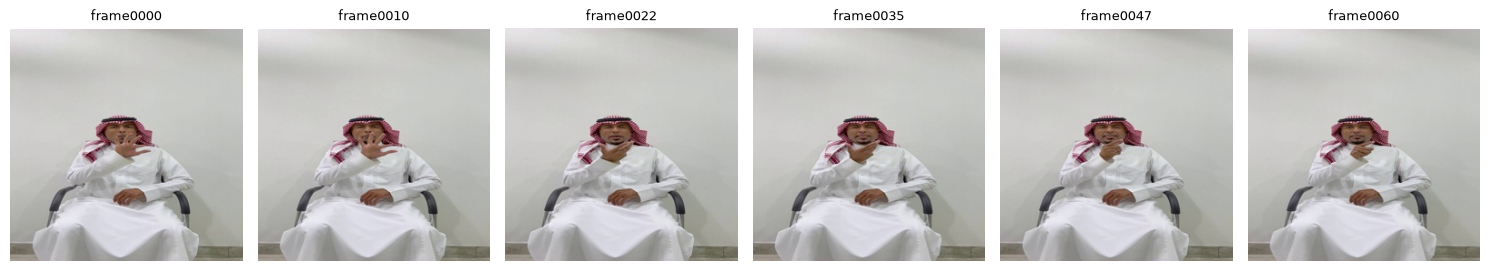

In [ ]:
def visualize_sampled_frames(frame_paths, display_count=6):
    """Display evenly spaced frames from a sampled sequence."""
    if not frame_paths:
        raise ValueError("Frame paths cannot be empty.")
    if display_count <= 0:
        raise ValueError("Display count must be positive.")
    selected_indices = np.linspace(
        0,
        len(frame_paths) - 1,
        num=min(display_count, len(frame_paths)),
        dtype=int,
    )
    figure, axes = plt.subplots(
        1,
        len(selected_indices),
        figsize=(15, 3),
        squeeze=False,
    )
    for axis, frame_index in zip(axes[0], selected_indices):
        frame_path = frame_paths[frame_index]
        image = plt.imread(frame_path)
        axis.imshow(image)
        axis.set_title(frame_path.stem, fontsize=9)
        axis.axis("off")
    plt.tight_layout()
    plt.show()
visualize_sampled_frames(sampled_frames)

In [ ]:
def check_image_quality(sample_directory):
    """Check image readability and dimensions for one sample."""
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    invalid_frames = []
    image_dimensions = set()
    for frame_path in frame_paths:
        try:
            with Image.open(frame_path) as image:
                image.load()
                image_dimensions.add(image.size)
        except (OSError, UnidentifiedImageError):
            invalid_frames.append(frame_path.name)
    return {
        "total_frames": len(frame_paths),
        "valid_frames": len(frame_paths) - len(invalid_frames),
        "invalid_frames": invalid_frames,
        "image_dimensions": sorted(image_dimensions),
    }
quality_results = check_image_quality(sample_directories[SAMPLE_ID])
print("Total frames:", quality_results["total_frames"])
print("Valid frames:", quality_results["valid_frames"])
print("Invalid frames:", len(quality_results["invalid_frames"]))
print("Image dimensions:", quality_results["image_dimensions"])

Total frames: 61
Valid frames: 61
Invalid frames: 0
Image dimensions: [(256, 256)]


In [ ]:
quality_reports = []
for sample_id, sample_directory in sorted(sample_directories.items()):
    result = check_image_quality(sample_directory)
    quality_reports.append({
        "sample_id": sample_id,
        "total_frames": result["total_frames"],
        "valid_frames": result["valid_frames"],
        "invalid_frames": len(result["invalid_frames"]),
        "image_dimensions": result["image_dimensions"],
    })
quality_df = pd.DataFrame(quality_reports)
print("Samples checked:", len(quality_df))
print("Total frames:", quality_df["total_frames"].sum())
print("Corrupted frames:", quality_df["invalid_frames"].sum())
print("Samples with corrupted frames:", (quality_df["invalid_frames"] > 0).sum())
print("Unique image dimensions:", quality_df["image_dimensions"].astype(str).unique())
display(quality_df.head())

Samples checked: 500
Total frames: 151363
Corrupted frames: 0
Samples with corrupted frames: 0
Unique image dimensions: <StringArray>
['[(256, 256)]']
Length: 1, dtype: str


,sample_id,total_frames,valid_frames,invalid_frames,image_dimensions
0,02_0001,61,61,0,"[(256, 256)]"
1,02_0002,291,291,0,"[(256, 256)]"
2,02_0003,176,176,0,"[(256, 256)]"
3,02_0004,356,356,0,"[(256, 256)]"
4,02_0005,184,184,0,"[(256, 256)]"


In [ ]:
report_directory = project / "reports"
report_directory.mkdir(parents=True, exist_ok=True)
report_path = report_directory / "isharah500_dev_quality.csv"
quality_df.to_csv(
    report_path,
    index=False,
    encoding="utf-8-sig",
)
print("Report saved:", report_path)
print("Samples in report:", len(quality_df))

Report saved: e:\DEPI Project\SIGNOVA_ESL\reports\isharah500_dev_quality.csv
Samples in report: 500


In [ ]:
print("MediaPipe version:", mp.__version__)
print("Tasks API available:", hasattr(mp, "tasks"))
print("Legacy Solutions API available:", hasattr(mp, "solutions"))
if hasattr(mp, "tasks"):
    print("Vision API available:", hasattr(mp.tasks, "vision"))

MediaPipe version: 1.1.1
Tasks API available: True
Legacy Solutions API available: False
Vision API available: True


In [ ]:
vision = mp.tasks.vision
print("Hand Landmarker:", hasattr(vision, "HandLandmarker"))
print("Hand Landmarker Options:", hasattr(vision, "HandLandmarkerOptions"))
print("Running Mode:", hasattr(vision, "RunningMode"))
print("Base Options:", hasattr(mp.tasks, "BaseOptions"))


Hand Landmarker: True
Hand Landmarker Options: True
Running Mode: True
Base Options: True


In [ ]:
model_path = project / "models" / "hand_landmarker.task"
if not model_path.is_file():
    raise FileNotFoundError(f"Model not found: {model_path}")
print("Model found:", model_path.name)
print("Model size (MB):", round(model_path.stat().st_size / 1024**2, 2))

Model found: hand_landmarker.task
Model size (MB): 7.46


In [ ]:
def extract_hand_keypoints(image_path, model_path):
    """Extract hand landmarks from a single image."""
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_hands=2,
    )
    image = mp.Image.create_from_file(str(image_path))
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        result = landmarker.detect(image)
    return result
image_path = sampled_frames[0]
hand_result = extract_hand_keypoints(image_path, model_path)
print("Image:", image_path.name)
print("Detected hands:", len(hand_result.hand_landmarks))

Image: frame0000.jpg
Detected hands: 1


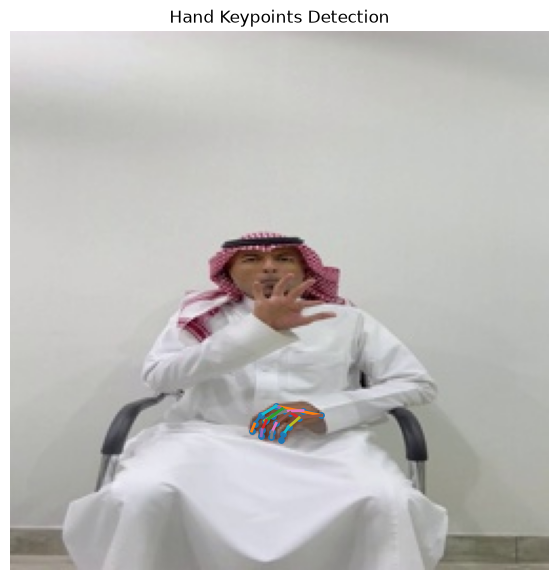

In [ ]:
def visualize_hand_keypoints(image_path, hand_landmarks):
    """Display detected hand landmarks on the original image."""
    image = plt.imread(image_path)
    plt.figure(figsize=(7, 7))
    plt.imshow(image)
    hand_connections = mp.tasks.vision.HandLandmarksConnections.HAND_CONNECTIONS
    for landmarks in hand_landmarks:
        x_coordinates = [landmark.x * image.shape[1] for landmark in landmarks]
        y_coordinates = [landmark.y * image.shape[0] for landmark in landmarks]
        for connection in hand_connections:
            start = connection.start
            end = connection.end
            plt.plot(
                [x_coordinates[start], x_coordinates[end]],
                [y_coordinates[start], y_coordinates[end]],
                linewidth=2,
            )
        plt.scatter(x_coordinates, y_coordinates, s=15)
    plt.axis("off")
    plt.title("Hand Keypoints Detection")
    plt.show()
visualize_hand_keypoints(image_path, hand_result.hand_landmarks)

In [ ]:
def evaluate_hand_detection(frame_paths, model_path):
    """Evaluate hand detection across multiple frames."""
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.IMAGE,
        num_hands=2,
    )
    results = []
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        for frame_path in frame_paths:
            image = mp.Image.create_from_file(str(frame_path))
            detection = landmarker.detect(image)
            results.append({
                "frame": frame_path.name,
                "detected_hands": len(detection.hand_landmarks),
            })
    return pd.DataFrame(results)
test_frames = sample_frame_paths(
    sample_directories[SAMPLE_ID],
    target_count=10,
)
detection_df = evaluate_hand_detection(test_frames, model_path)
display(detection_df)
print("\nDetection summary:")
print(detection_df["detected_hands"].value_counts().sort_index())

,frame,detected_hands
0,frame0000.jpg,1
1,frame0006.jpg,1
2,frame0013.jpg,1
3,frame0020.jpg,1
4,frame0026.jpg,1
5,frame0033.jpg,1
6,frame0040.jpg,1
7,frame0046.jpg,1
8,frame0053.jpg,1
9,frame0060.jpg,1



Detection summary:
detected_hands
1    10
Name: count, dtype: int64


In [ ]:
def evaluate_video_hand_detection(sample_directory, model_path, fps=30):
    """Evaluate hand detection using sequential video frames."""
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=2,
    )
    results = []
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        for frame_index, frame_path in enumerate(frame_paths):
            image = mp.Image.create_from_file(str(frame_path))
            timestamp_ms = round(frame_index * 1000 / fps)
            detection = landmarker.detect_for_video(
                image,
                timestamp_ms,
            )
            results.append({
                "frame": frame_path.name,
                "detected_hands": len(detection.hand_landmarks),
            })
    return pd.DataFrame(results)
video_detection_df = evaluate_video_hand_detection(
    sample_directories[SAMPLE_ID],
    model_path,
)
print("Total frames:", len(video_detection_df))
print("\nDetection summary:")
print(video_detection_df["detected_hands"].value_counts().sort_index())
display(video_detection_df.head(10))

Total frames: 61

Detection summary:
detected_hands
1    61
Name: count, dtype: int64


,frame,detected_hands
0,frame0000.jpg,1
1,frame0001.jpg,1
2,frame0002.jpg,1
3,frame0003.jpg,1
4,frame0004.jpg,1
5,frame0005.jpg,1
6,frame0006.jpg,1
7,frame0007.jpg,1
8,frame0008.jpg,1
9,frame0009.jpg,1


In [ ]:
def evaluate_detection_threshold(
    sample_directory,
    model_path,
    confidence_threshold=0.3,
    fps=30,
):
    """Evaluate hand detection with configurable confidence thresholds."""
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=confidence_threshold,
        min_hand_presence_confidence=confidence_threshold,
        min_tracking_confidence=confidence_threshold,
    )
    results = []
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        for frame_index, frame_path in enumerate(frame_paths):
            image = mp.Image.create_from_file(str(frame_path))
            timestamp_ms = round(frame_index * 1000 / fps)
            detection = landmarker.detect_for_video(
                image,
                timestamp_ms,
            )
            results.append({
                "frame": frame_path.name,
                "detected_hands": len(detection.hand_landmarks),
            })
    return pd.DataFrame(results)
low_confidence_df = evaluate_detection_threshold(
    sample_directories[SAMPLE_ID],
    model_path,
    confidence_threshold=0.3,
)
print("Detection summary:")
print(low_confidence_df["detected_hands"].value_counts().sort_index())
print("\nFrames with two detected hands:")
print((low_confidence_df["detected_hands"] == 2).sum())

Detection summary:
detected_hands
1    26
2    35
Name: count, dtype: int64

Frames with two detected hands:
35


Frame: frame0026.jpg
Detected hands: 2


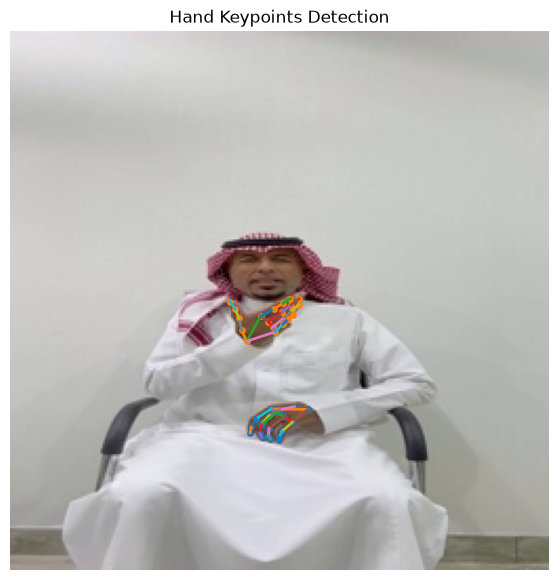

In [ ]:
two_hand_frames = low_confidence_df.loc[
    low_confidence_df["detected_hands"] == 2,
    "frame",
]
if two_hand_frames.empty:
    print("No frames with two detected hands.")
else:
    target_frame_name = two_hand_frames.iloc[0]
    target_frame_path = sample_directories[SAMPLE_ID] / target_frame_name
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=2,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
        min_tracking_confidence=0.3,
    )
    frame_paths = sorted(sample_directories[SAMPLE_ID].glob("*.jpg"))
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        for frame_index, frame_path in enumerate(frame_paths):
            image = mp.Image.create_from_file(str(frame_path))
            detection = landmarker.detect_for_video(
                image,
                round(frame_index * 1000 / 30),
            )
            if frame_path.name == target_frame_name:
                print("Frame:", frame_path.name)
                print("Detected hands:", len(detection.hand_landmarks))
                visualize_hand_keypoints(
                    frame_path,
                    detection.hand_landmarks,
                )
                break

In [ ]:
HAND_COUNT = 2
LANDMARKS_PER_HAND = 21
COORDINATES_PER_LANDMARK = 3
HAND_FEATURE_COUNT = LANDMARKS_PER_HAND * COORDINATES_PER_LANDMARK
HAND_LABEL_TO_INDEX = {
    "Left": 0,
    "Right": 1,
}
def extract_sample_hand_keypoints(sample_directory, model_path, fps=30):
    """Extract temporally ordered keypoints with consistent hand slots."""
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    if not frame_paths:
        raise ValueError(f"No JPG frames found in {sample_directory}")
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=HAND_COUNT,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
        min_tracking_confidence=0.3,
    )
    keypoint_sequences = []
    detection_counts = []
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        for frame_index, frame_path in enumerate(frame_paths):
            image = mp.Image.create_from_file(str(frame_path))
            timestamp_ms = round(frame_index * 1000 / fps)
            result = landmarker.detect_for_video(image, timestamp_ms)
            frame_keypoints = np.full(
                (HAND_COUNT, HAND_FEATURE_COUNT),
                np.nan,
                dtype=np.float32,
            )
            for landmarks, handedness in zip(
                result.hand_landmarks,
                result.handedness,
            ):
                hand_label = handedness[0].category_name
                hand_index = HAND_LABEL_TO_INDEX.get(hand_label)
                if hand_index is None:
                    continue
                coordinates = [
                    coordinate
                    for landmark in landmarks
                    for coordinate in (landmark.x, landmark.y, landmark.z)
                ]
                frame_keypoints[hand_index] = coordinates
            keypoint_sequences.append(frame_keypoints)
            detection_counts.append(len(result.hand_landmarks))
    return (
        np.stack(keypoint_sequences),
        np.asarray(detection_counts, dtype=np.int32),
    )
sample_keypoints, sample_detection_counts = extract_sample_hand_keypoints(
    sample_directories[SAMPLE_ID],
    model_path,
)
print("Keypoints shape:", sample_keypoints.shape)
print("Missing values:", np.isnan(sample_keypoints).sum())
for hand_label, hand_index in HAND_LABEL_TO_INDEX.items():
    detected_frames = np.isfinite(
        sample_keypoints[:, hand_index, :]
    ).all(axis=1).sum()
    print(f"{hand_label} hand detected in:", detected_frames, "frames")

Keypoints shape: (61, 2, 63)
Missing values: 1638
Left hand detected in: 61 frames
Right hand detected in: 35 frames


In [ ]:
keypoints_directory = (
    project / "data" / "processed" / "isharah500" / "hand_keypoints" / "dev"
)
keypoints_directory.mkdir(parents=True, exist_ok=True)
output_path = keypoints_directory / f"{SAMPLE_ID}.npy"
np.save(output_path, sample_keypoints)
saved_keypoints = np.load(output_path)
if not np.array_equal(sample_keypoints, saved_keypoints, equal_nan=True):
    raise ValueError("Saved keypoints do not match the original data.")
print("Saved:", output_path)
print("Shape:", saved_keypoints.shape)
print("Data type:", saved_keypoints.dtype)
print("Missing values:", np.isnan(saved_keypoints).sum())

Saved: e:\DEPI Project\SIGNOVA_ESL\data\processed\isharah500\hand_keypoints\dev\02_0001.npy
Shape: (61, 2, 63)
Data type: float32
Missing values: 1638


In [ ]:
test_sample_ids = ["02_0002", "02_0003", "02_0004"]
test_results = []
for sample_id in test_sample_ids:
    keypoints, detection_counts = extract_sample_hand_keypoints(
        sample_directories[sample_id],
        model_path,
    )
    test_results.append({
        "sample_id": sample_id,
        "frames": len(keypoints),
        "keypoints_shape": keypoints.shape,
        "two_hand_frames": int((detection_counts == 2).sum()),
        "one_hand_frames": int((detection_counts == 1).sum()),
        "zero_hand_frames": int((detection_counts == 0).sum()),
    })
test_results_df = pd.DataFrame(test_results)
display(test_results_df)

,sample_id,frames,keypoints_shape,two_hand_frames,one_hand_frames,zero_hand_frames
0,02_0002,291,"(291, 2, 63)",120,170,1
1,02_0003,176,"(176, 2, 63)",92,84,0
2,02_0004,356,"(356, 2, 63)",197,158,1


In [ ]:
extraction_reports = []
for sample_index, (sample_id, sample_directory) in enumerate(
    sorted(sample_directories.items()),
    start=1,
):
    output_path = keypoints_directory / f"{sample_id}.npy"
    if output_path.exists():
        continue
    keypoints, detection_counts = extract_sample_hand_keypoints(
        sample_directory,
        model_path,
    )
    np.save(output_path, keypoints)
    extraction_reports.append({
        "sample_id": sample_id,
        "frame_count": len(keypoints),
        "two_hand_frames": int((detection_counts == 2).sum()),
        "one_hand_frames": int((detection_counts == 1).sum()),
        "zero_hand_frames": int((detection_counts == 0).sum()),
        "missing_values": int(np.isnan(keypoints).sum()),
    })
    if sample_index % 25 == 0:
        print(f"Processed {sample_index}/{len(sample_directories)} samples")
extraction_report_df = pd.DataFrame(extraction_reports)
report_path = project / "reports" / "isharah500_dev_keypoints.csv"
extraction_report_df.to_csv(report_path, index=False)
print("Newly processed samples:", len(extraction_report_df))
print("Report saved:", report_path)

Processed 25/500 samples
Processed 50/500 samples
Processed 75/500 samples
Processed 100/500 samples
Processed 125/500 samples
Processed 150/500 samples
Processed 175/500 samples
Processed 200/500 samples
Processed 225/500 samples
Processed 250/500 samples
Processed 275/500 samples
Processed 300/500 samples
Processed 325/500 samples
Processed 350/500 samples
Processed 375/500 samples
Processed 400/500 samples
Processed 425/500 samples
Processed 450/500 samples
Processed 475/500 samples
Processed 500/500 samples
Newly processed samples: 499
Report saved: e:\DEPI Project\SIGNOVA_ESL\reports\isharah500_dev_keypoints.csv


In [ ]:
validation_results = []
for sample_id, sample_directory in sorted(sample_directories.items()):
    file_path = keypoints_directory / f"{sample_id}.npy"
    expected_frames = frame_counts[sample_id]
    if not file_path.is_file():
        validation_results.append({
            "sample_id": sample_id,
            "status": "missing",
        })
        continue
    try:
        keypoints = np.load(file_path, allow_pickle=False)
        valid_shape = keypoints.shape == (
            expected_frames,
            HAND_COUNT,
            HAND_FEATURE_COUNT,
        )
        valid_dtype = keypoints.dtype == np.float32
        valid_values = np.isfinite(keypoints) | np.isnan(keypoints)
        status = (
            "valid"
            if valid_shape and valid_dtype and valid_values.all()
            else "invalid"
        )
    except (OSError, ValueError) as error:
        status = "invalid"
    validation_results.append({
        "sample_id": sample_id,
        "status": status,
    })
validation_df = pd.DataFrame(validation_results)
print("Expected samples:", len(sample_directories))
print("Valid files:", (validation_df["status"] == "valid").sum())
print("Missing files:", (validation_df["status"] == "missing").sum())
print("Invalid files:", (validation_df["status"] == "invalid").sum())
display(validation_df["status"].value_counts())

Expected samples: 500
Valid files: 500
Missing files: 0
Invalid files: 0


status
valid    500
Name: count, dtype: int64

In [ ]:
detection_reports = []
for sample_id in sorted(sample_directories):
    file_path = keypoints_directory / f"{sample_id}.npy"
    keypoints = np.load(file_path, allow_pickle=False)
    detected_hands = np.isfinite(keypoints).all(axis=2).sum(axis=1)
    total_frames = len(keypoints)
    detection_reports.append({
        "sample_id": sample_id,
        "total_frames": total_frames,
        "two_hands_pct": round(
            100 * np.mean(detected_hands == 2), 2
        ),
        "one_hand_pct": round(
            100 * np.mean(detected_hands == 1), 2
        ),
        "zero_hands_pct": round(
            100 * np.mean(detected_hands == 0), 2
        ),
    })
detection_quality_df = pd.DataFrame(detection_reports)
report_path = (
    project / "reports" / "isharah500_dev_detection_quality.csv"
)
detection_quality_df.to_csv(report_path, index=False)
print("Samples analyzed:", len(detection_quality_df))
print(
    "Average two-hand detection:",
    round(detection_quality_df["two_hands_pct"].mean(), 2),
    "%",
)
print(
    "Average zero-hand detection:",
    round(detection_quality_df["zero_hands_pct"].mean(), 2),
    "%",
)
print("\nLowest two-hand detection samples:")
display(detection_quality_df.nsmallest(10, "two_hands_pct"))

Samples analyzed: 500
Average two-hand detection: 46.65 %
Average zero-hand detection: 0.98 %

Lowest two-hand detection samples:


,sample_id,total_frames,two_hands_pct,one_hand_pct,zero_hands_pct
38,02_0039,235,2.55,96.17,1.28
424,02_0425,352,7.10,92.61,0.28
82,02_0083,237,7.59,91.98,0.42
139,02_0140,271,7.75,91.88,0.37
137,02_0138,379,8.44,88.65,2.90
83,02_0084,319,9.72,90.28,0.00
130,02_0131,408,12.25,85.78,1.96
41,02_0042,322,12.42,86.96,0.62
60,02_0061,494,13.36,86.03,0.61
190,02_0191,301,13.62,86.05,0.33


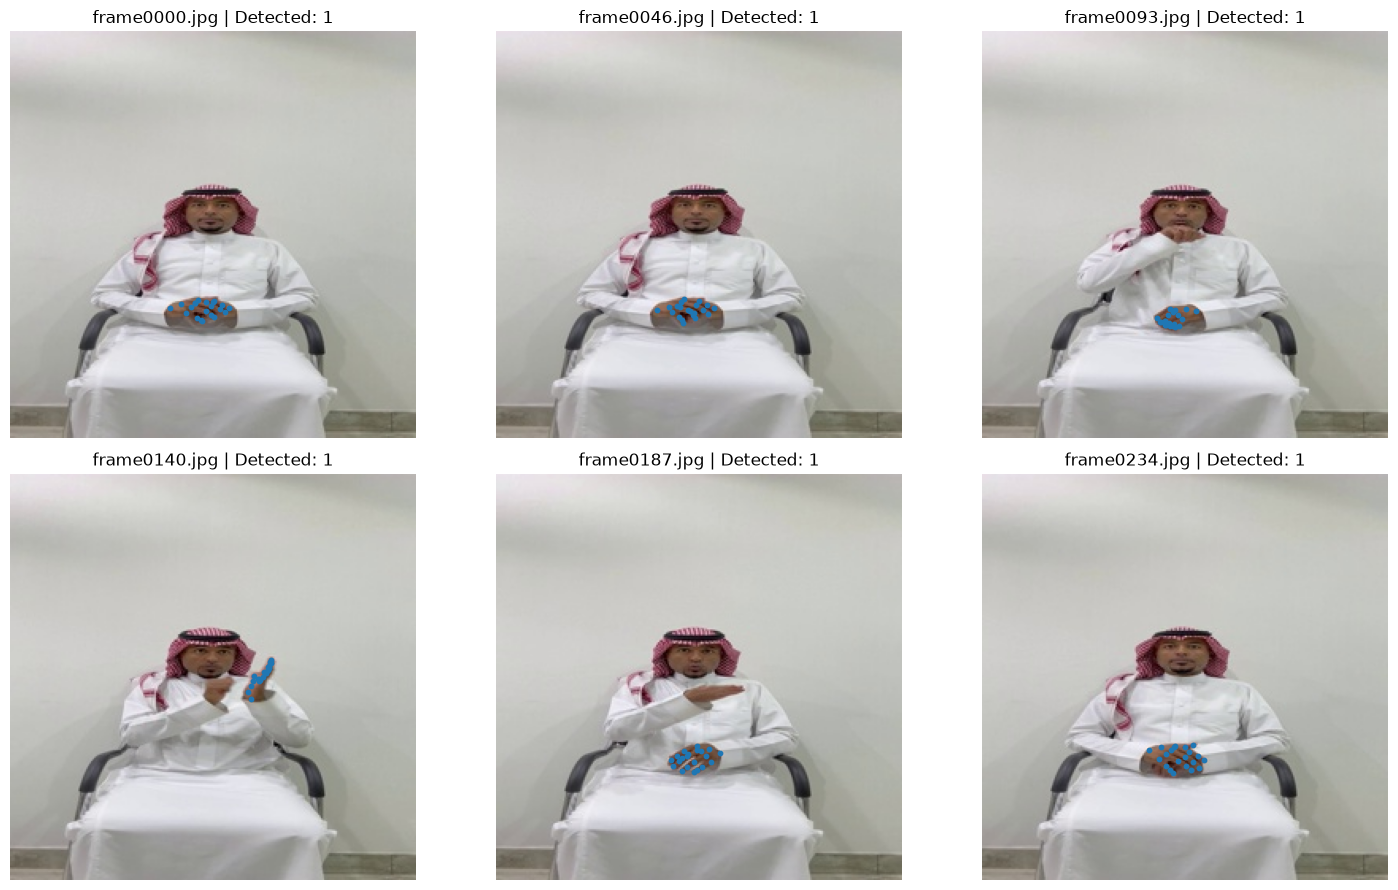

In [ ]:
review_sample_id = "02_0039"
review_frames = sample_frame_paths(
    sample_directories[review_sample_id],
    target_count=6,
)
review_keypoints = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
all_frame_paths = sorted(
    sample_directories[review_sample_id].glob("*.jpg")
)
frame_indices = {
    frame_path.name: index
    for index, frame_path in enumerate(all_frame_paths)
}
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, frame_path in zip(axes.flat, review_frames):
    frame_index = frame_indices[frame_path.name]
    image = plt.imread(frame_path)
    frame_keypoints = review_keypoints[frame_index]
    axis.imshow(image)
    for hand_index in range(HAND_COUNT):
        landmarks = frame_keypoints[hand_index].reshape(
            LANDMARKS_PER_HAND,
            COORDINATES_PER_LANDMARK,
        )
        if np.isnan(landmarks).any():
            continue
        axis.scatter(
            landmarks[:, 0] * image.shape[1],
            landmarks[:, 1] * image.shape[0],
            s=10,
        )
    detected_hands = np.isfinite(frame_keypoints).all(axis=1).sum()
    axis.set_title(
        f"{frame_path.name} | Detected: {detected_hands}"
    )
    axis.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
detection_thresholds = [10, 25, 50, 75]
for threshold in detection_thresholds:
    sample_count = (
        detection_quality_df["two_hands_pct"] < threshold
    ).sum()
    print(
        f"Samples below {threshold}% two-hand detection: "
        f"{sample_count}"
    )
print("\nOverall detection statistics:")
display(
    detection_quality_df[
        ["two_hands_pct", "one_hand_pct", "zero_hands_pct"]
    ].describe().round(2)
)

Samples below 10% two-hand detection: 6
Samples below 25% two-hand detection: 59
Samples below 50% two-hand detection: 275
Samples below 75% two-hand detection: 481

Overall detection statistics:


,two_hands_pct,one_hand_pct,zero_hands_pct
count,500.00,500.00,500.00
mean,46.65,52.37,0.98
std,16.82,16.67,2.85
min,2.55,11.81,0.00
25%,34.44,40.18,0.00
50%,47.28,51.80,0.00
75%,58.17,64.38,0.60
max,88.19,96.17,32.20


In [ ]:
high_risk_samples = detection_quality_df[
    (detection_quality_df["zero_hands_pct"] >= 10)
    | (detection_quality_df["two_hands_pct"] < 10)
].copy()
high_risk_samples = high_risk_samples.sort_values(
    by=["zero_hands_pct", "two_hands_pct"],
    ascending=[False, True],
)
print("High-risk samples:", len(high_risk_samples))
display(high_risk_samples.head(15))

High-risk samples: 15


,sample_id,total_frames,two_hands_pct,one_hand_pct,zero_hands_pct
330,02_0331,295,48.81,18.98,32.20
361,02_0362,227,55.07,18.94,25.99
443,02_0444,304,48.36,32.89,18.75
85,02_0086,210,14.76,68.10,17.14
421,02_0422,253,59.29,24.90,15.81
298,02_0299,237,63.29,22.78,13.92
458,02_0459,226,24.34,63.27,12.39
84,02_0085,379,19.53,68.60,11.87
209,02_0210,253,44.27,43.87,11.86
137,02_0138,379,8.44,88.65,2.90


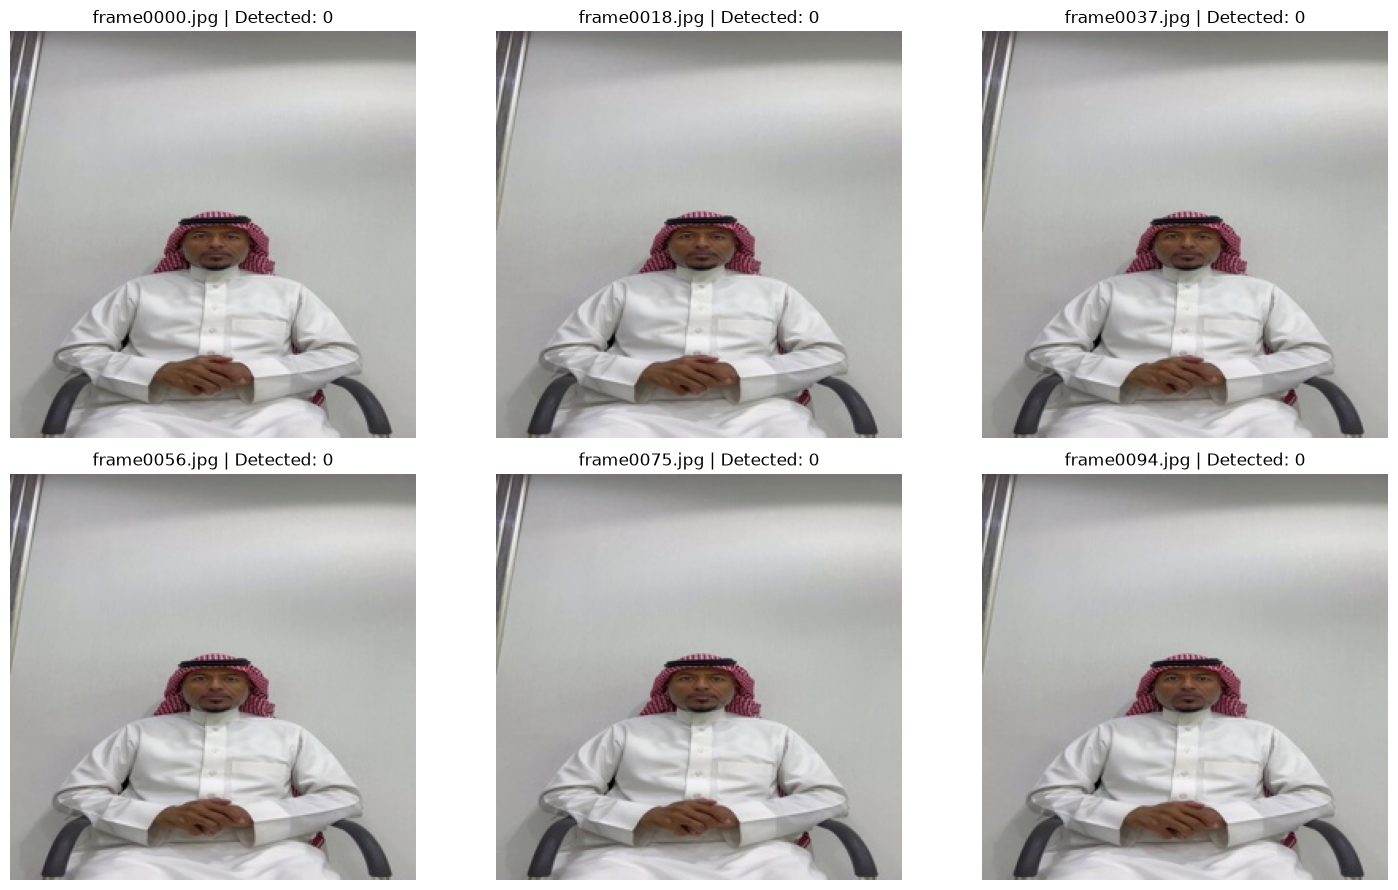

In [ ]:
review_sample_id = "02_0331"
review_keypoints = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
frame_paths = sorted(
    sample_directories[review_sample_id].glob("*.jpg")
)
detected_hands = np.isfinite(review_keypoints).all(axis=2).sum(axis=1)
missing_frame_indices = np.flatnonzero(detected_hands == 0)
selected_indices = missing_frame_indices[
    np.linspace(
        0,
        len(missing_frame_indices) - 1,
        num=min(6, len(missing_frame_indices)),
        dtype=int,
    )
]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis in axes.flat:
    axis.axis("off")
for axis, frame_index in zip(axes.flat, selected_indices):
    frame_path = frame_paths[frame_index]
    axis.imshow(plt.imread(frame_path))
    axis.set_title(f"{frame_path.name} | Detected: 0")
    axis.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
review_report_path = (
    project / "reports" / "isharah500_dev_review_required.csv"
)
high_risk_samples.to_csv(
    review_report_path,
    index=False,
    encoding="utf-8-sig",
)
print("Review report saved:", review_report_path)
print("Samples requiring review:", len(high_risk_samples))
print("Total validated keypoint files:", len(validation_df))

Review report saved: e:\DEPI Project\SIGNOVA_ESL\reports\isharah500_dev_review_required.csv
Samples requiring review: 15
Total validated keypoint files: 500


In [ ]:
review_sample_id = "02_0331"
confidence_thresholds = [0.2, 0.3, 0.5]
comparison_results = []
for threshold in confidence_thresholds:
    detection_df = evaluate_detection_threshold(
        sample_directories[review_sample_id],
        model_path,
        confidence_threshold=threshold,
    )
    comparison_results.append({
        "confidence": threshold,
        "two_hands_pct": round(
            100 * (detection_df["detected_hands"] == 2).mean(),
            2,
        ),
        "one_hand_pct": round(
            100 * (detection_df["detected_hands"] == 1).mean(),
            2,
        ),
        "zero_hands_pct": round(
            100 * (detection_df["detected_hands"] == 0).mean(),
            2,
        ),
    })
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,confidence,two_hands_pct,one_hand_pct,zero_hands_pct
0,0.2,54.92,11.53,33.56
1,0.3,52.88,14.92,32.20
2,0.5,52.54,47.46,0.00


In [ ]:
review_sample_id = "02_0331"
sample_directory = sample_directories[review_sample_id]
frame_paths = sorted(sample_directory.glob("*.jpg"))
keypoints = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
detected_hands = np.isfinite(keypoints).all(axis=2).sum(axis=1)
missing_indices = np.flatnonzero(detected_hands == 0)
selected_indices = missing_indices[
    np.linspace(
        0,
        len(missing_indices) - 1,
        num=min(6, len(missing_indices)),
        dtype=int,
    )
]
comparison_frames = []
for threshold in (0.3, 0.5):
    results = evaluate_detection_threshold(
        sample_directory,
        model_path,
        confidence_threshold=threshold,
    )
    for frame_index in selected_indices:
        comparison_frames.append({
            "frame": frame_paths[frame_index].name,
            "confidence": threshold,
            "detected_hands": int(
                results.iloc[frame_index]["detected_hands"]
            ),
        })
comparison_frames_df = pd.DataFrame(comparison_frames)
display(
    comparison_frames_df.pivot(
        index="frame",
        columns="confidence",
        values="detected_hands",
    )
)

confidence,0.3,0.5
frame,,
frame0000.jpg,0,1
frame0018.jpg,0,1
frame0037.jpg,0,1
frame0056.jpg,0,1
frame0075.jpg,0,1
frame0094.jpg,0,1


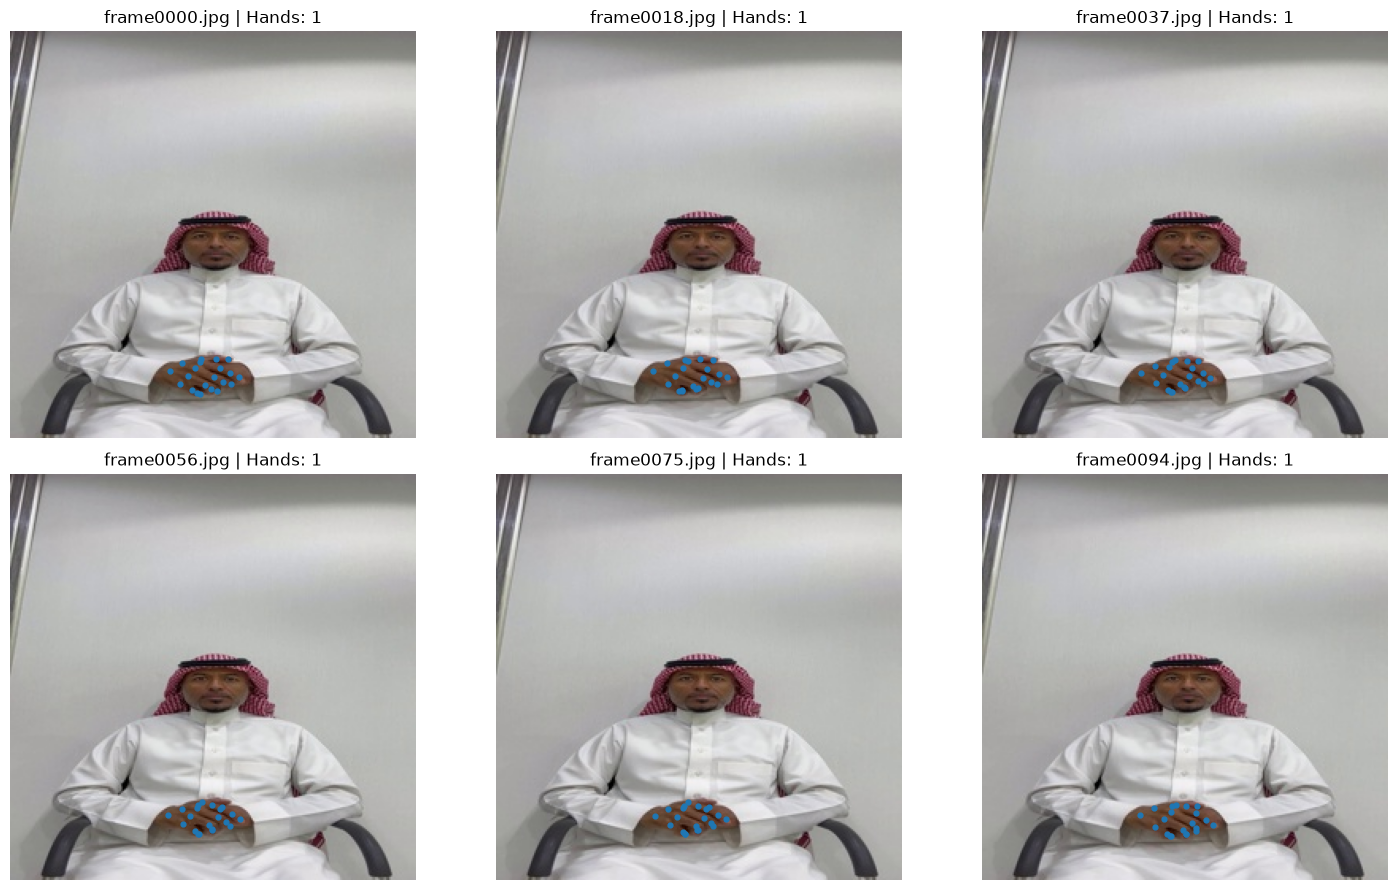

In [ ]:
options = mp.tasks.vision.HandLandmarkerOptions(
    base_options=mp.tasks.BaseOptions(
        model_asset_path=str(model_path)
    ),
    running_mode=mp.tasks.vision.RunningMode.VIDEO,
    num_hands=2,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)
selected_frame_indices = set(selected_indices.tolist())
selected_detections = {}
with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
    for frame_index, frame_path in enumerate(frame_paths):
        image = mp.Image.create_from_file(str(frame_path))
        result = landmarker.detect_for_video(
            image,
            round(frame_index * 1000 / 30),
        )
        if frame_index in selected_frame_indices:
            selected_detections[frame_index] = result.hand_landmarks
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for axis, frame_index in zip(axes.flat, selected_indices):
    frame_path = frame_paths[frame_index]
    image = plt.imread(frame_path)
    axis.imshow(image)
    for landmarks in selected_detections[frame_index]:
        x_coordinates = [
            landmark.x * image.shape[1]
            for landmark in landmarks
        ]
        y_coordinates = [
            landmark.y * image.shape[0]
            for landmark in landmarks
        ]
        axis.scatter(x_coordinates, y_coordinates, s=12)
    axis.set_title(
        f"{frame_path.name} | Hands: "
        f"{len(selected_detections[frame_index])}"
    )
    axis.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
test_sample_ids = [
    "02_0001",
    "02_0039",
    "02_0331",
    "02_0362",
    "02_0425",
]
comparison_results = []
for sample_id in test_sample_ids:
    for threshold in (0.3, 0.5):
        result_df = evaluate_detection_threshold(
            sample_directories[sample_id],
            model_path,
            confidence_threshold=threshold,
        )
        comparison_results.append({
            "sample_id": sample_id,
            "confidence": threshold,
            "two_hands_pct": round(
                100 * (result_df["detected_hands"] == 2).mean(),
                2,
            ),
            "zero_hands_pct": round(
                100 * (result_df["detected_hands"] == 0).mean(),
                2,
            ),
        })
comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,sample_id,confidence,two_hands_pct,zero_hands_pct
0,02_0001,0.3,57.38,0.00
1,02_0001,0.5,0.00,0.00
2,02_0039,0.3,2.55,1.28
3,02_0039,0.5,3.83,2.98
4,02_0331,0.3,52.88,32.20
5,02_0331,0.5,52.54,0.00
6,02_0362,0.3,59.03,25.99
7,02_0362,0.5,55.51,0.00
8,02_0425,0.3,50.85,0.28
9,02_0425,0.5,86.36,0.85


In [ ]:
recovery_results = []
for sample_id in test_sample_ids:
    sample_directory = sample_directories[sample_id]
    low_confidence = evaluate_detection_threshold(
        sample_directory,
        model_path,
        confidence_threshold=0.3,
    )
    high_confidence = evaluate_detection_threshold(
        sample_directory,
        model_path,
        confidence_threshold=0.5,
    )
    recovered_frames = (
        (low_confidence["detected_hands"] == 0)
        & (high_confidence["detected_hands"] > 0)
    ).sum()
    recovery_results.append({
        "sample_id": sample_id,
        "total_frames": len(low_confidence),
        "missing_at_03": int(
            (low_confidence["detected_hands"] == 0).sum()
        ),
        "recovered_frames": int(recovered_frames),
        "remaining_missing": int(
            (
                (low_confidence["detected_hands"] == 0)
                & (high_confidence["detected_hands"] == 0)
            ).sum()
        ),
    })
recovery_df = pd.DataFrame(recovery_results)
display(recovery_df)

,sample_id,total_frames,missing_at_03,recovered_frames,remaining_missing
0,02_0001,61,0,0,0
1,02_0039,235,3,1,2
2,02_0331,295,95,95,0
3,02_0362,227,59,59,0
4,02_0425,352,1,0,1


In [ ]:
def calculate_hand_motion(keypoints):
    """Calculate wrist displacement between consecutive frames."""
    wrist_positions = keypoints[:, :, :2]
    previous_positions = wrist_positions[:-1]
    current_positions = wrist_positions[1:]
    valid_pairs = (
        np.isfinite(previous_positions).all(axis=2)
        & np.isfinite(current_positions).all(axis=2)
    )
    distances = np.linalg.norm(
        current_positions - previous_positions,
        axis=2,
    )
    return np.where(valid_pairs, distances, np.nan)
motion_results = []
for sample_id in test_sample_ids:
    keypoints = np.load(
        keypoints_directory / f"{sample_id}.npy",
        allow_pickle=False,
    )
    motion = calculate_hand_motion(keypoints)
    valid_motion = motion[np.isfinite(motion)]
    motion_results.append({
        "sample_id": sample_id,
        "max_wrist_displacement": round(
            float(valid_motion.max()), 4
        ) if valid_motion.size else np.nan,
        "p95_wrist_displacement": round(
            float(np.percentile(valid_motion, 95)), 4
        ) if valid_motion.size else np.nan,
    })
motion_df = pd.DataFrame(motion_results)
display(motion_df)

,sample_id,max_wrist_displacement,p95_wrist_displacement
0,02_0001,0.0090,0.0068
1,02_0039,0.0175,0.0110
2,02_0331,0.2824,0.0218
3,02_0362,0.2877,0.0146
4,02_0425,0.5602,0.1396


In [ ]:
JUMP_REVIEW_THRESHOLD = 0.15
suspicious_jumps = []
for sample_id in test_sample_ids:
    keypoints = np.load(
        keypoints_directory / f"{sample_id}.npy",
        allow_pickle=False,
    )
    motion = calculate_hand_motion(keypoints)
    frame_indices, hand_indices = np.where(
        motion > JUMP_REVIEW_THRESHOLD
    )
    for frame_index, hand_index in zip(frame_indices, hand_indices):
        suspicious_jumps.append({
            "sample_id": sample_id,
            "frame_before": frame_index,
            "frame_after": frame_index + 1,
            "hand_slot": hand_index,
            "displacement": round(
                float(motion[frame_index, hand_index]), 4
            ),
        })
suspicious_jumps_df = pd.DataFrame(
    suspicious_jumps,
    columns=[
        "sample_id",
        "frame_before",
        "frame_after",
        "hand_slot",
        "displacement",
    ],
)
print("Suspicious jumps:", len(suspicious_jumps_df))
display(
    suspicious_jumps_df.sort_values(
        "displacement",
        ascending=False,
    ).head(10)
)

Suspicious jumps: 37


,sample_id,frame_before,frame_after,hand_slot,displacement
25,02_0425,146,147,1,0.5602
26,02_0425,148,149,1,0.5571
27,02_0425,152,153,1,0.5487
28,02_0425,161,162,1,0.4941
24,02_0425,140,141,1,0.4830
23,02_0425,139,140,1,0.4651
22,02_0425,134,135,0,0.4279
21,02_0425,133,134,0,0.4024
29,02_0425,180,181,1,0.3459
31,02_0425,184,185,1,0.3406


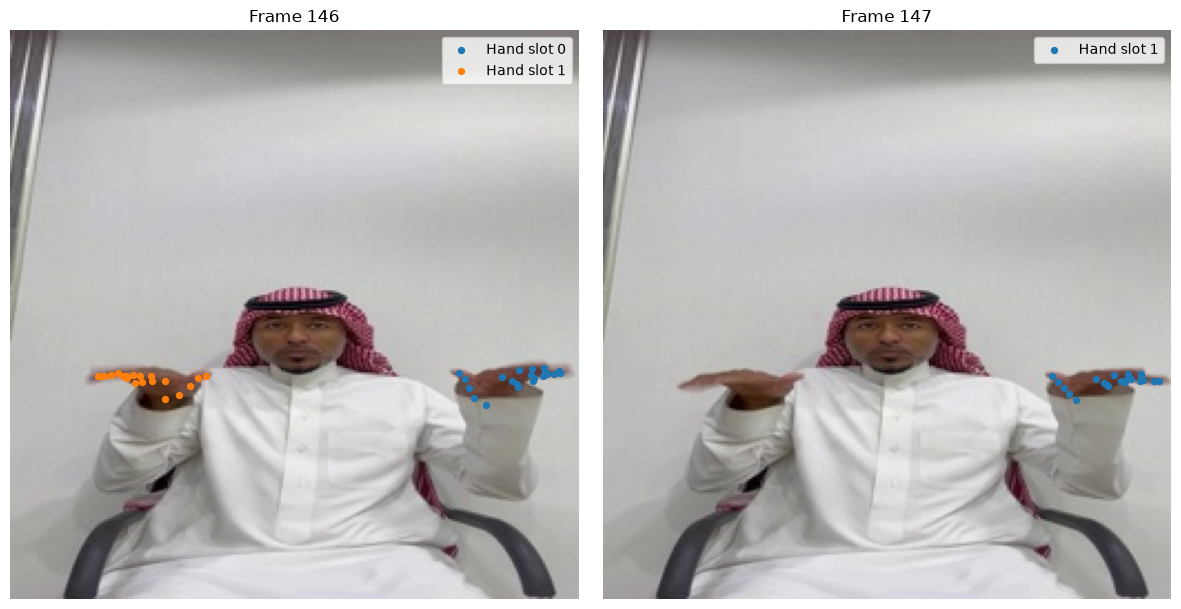

In [ ]:
largest_jump = suspicious_jumps_df.loc[
    suspicious_jumps_df["displacement"].idxmax()
]
review_sample_id = largest_jump["sample_id"]
frame_indices = [
    int(largest_jump["frame_before"]),
    int(largest_jump["frame_after"]),
]
review_keypoints = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
review_frame_paths = sorted(
    sample_directories[review_sample_id].glob("*.jpg")
)
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for axis, frame_index in zip(axes, frame_indices):
    image = plt.imread(review_frame_paths[frame_index])
    axis.imshow(image)
    for hand_index in range(HAND_COUNT):
        landmarks = review_keypoints[
            frame_index, hand_index
        ].reshape(LANDMARKS_PER_HAND, COORDINATES_PER_LANDMARK)
        if not np.isfinite(landmarks).all():
            continue
        axis.scatter(
            landmarks[:, 0] * image.shape[1],
            landmarks[:, 1] * image.shape[0],
            s=18,
            label=f"Hand slot {hand_index}",
        )
    axis.set_title(f"Frame {frame_index}")
    axis.legend()
    axis.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
review_sample_id = "02_0425"
review_keypoints = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
for frame_index in (146, 147):
    print(f"\nFrame {frame_index}")
    for hand_label, hand_index in HAND_LABEL_TO_INDEX.items():
        wrist_coordinates = review_keypoints[
            frame_index, hand_index, :3
        ]
        print(
            f"{hand_label}: "
            f"{np.round(wrist_coordinates, 4)}"
        )


Frame 146
Left: [0.8345 0.6567 0.    ]
Right: [0.2702 0.6466 0.    ]

Frame 147
Left: [nan nan nan]
Right: [0.8304 0.6483 0.    ]


In [ ]:
def correct_hand_slots(keypoints, max_distance=0.15):
    """Correct hand-slot swaps using consecutive wrist positions."""
    corrected = keypoints.copy()
    for frame_index in range(1, len(corrected)):
        previous = corrected[frame_index - 1]
        current = corrected[frame_index].copy()
        previous_wrists = previous[:, :2]
        current_wrists = current[:, :2]
        previous_valid = np.isfinite(previous_wrists).all(axis=1)
        current_valid = np.isfinite(current_wrists).all(axis=1)
        if previous_valid.sum() != 2 or current_valid.sum() != 1:
            continue
        detected_slot = int(np.flatnonzero(current_valid)[0])
        detected_wrist = current_wrists[detected_slot]
        distances = np.linalg.norm(
            previous_wrists - detected_wrist,
            axis=1,
        )
        nearest_slot = int(np.argmin(distances))
        if distances[nearest_slot] > max_distance:
            continue
        if nearest_slot != detected_slot:
            corrected[frame_index] = np.nan
            corrected[frame_index, nearest_slot] = current[detected_slot]
    return corrected
review_sample_id = "02_0425"
original_keypoints = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
corrected_keypoints = correct_hand_slots(original_keypoints)
print("Frame 146:")
print("Original:", original_keypoints[146, :, :2])
print("Corrected:", corrected_keypoints[146, :, :2])
print("\nFrame 147:")
print("Original:", original_keypoints[147, :, :2])
print("Corrected:", corrected_keypoints[147, :, :2])

Frame 146:
Original: [[0.834511   0.65672475]
 [0.27020717 0.6465727 ]]
Corrected: [[0.834511   0.65672475]
 [0.27020717 0.6465727 ]]

Frame 147:
Original: [[       nan        nan]
 [0.83040196 0.64831716]]
Corrected: [[0.83040196 0.64831716]
 [       nan        nan]]


In [ ]:
original_motion = calculate_hand_motion(original_keypoints)
corrected_motion = calculate_hand_motion(corrected_keypoints)
def summarize_motion(motion):
    """Summarize valid wrist displacement values."""
    valid_motion = motion[np.isfinite(motion)]
    return {
        "max_displacement": round(float(valid_motion.max()), 4),
        "p95_displacement": round(
            float(np.percentile(valid_motion, 95)), 4
        ),
        "large_jumps": int((valid_motion > 0.15).sum()),
        "valid_transitions": len(valid_motion),
    }
motion_comparison_df = pd.DataFrame({
    "Before": summarize_motion(original_motion),
    "After": summarize_motion(corrected_motion),
}).T
display(motion_comparison_df)

,max_displacement,p95_displacement,large_jumps,valid_transitions
Before,0.5602,0.1396,17.0,353.0
After,0.5571,0.0228,12.0,347.0


In [ ]:
remaining_jumps = []
frame_indices, hand_indices = np.where(
    corrected_motion > JUMP_REVIEW_THRESHOLD
)
for frame_index, hand_index in zip(frame_indices, hand_indices):
    remaining_jumps.append({
        "frame_before": int(frame_index),
        "frame_after": int(frame_index + 1),
        "hand_slot": int(hand_index),
        "displacement": float(
            corrected_motion[frame_index, hand_index]
        ),
    })
remaining_jumps_df = pd.DataFrame(
    remaining_jumps,
    columns=[
        "frame_before",
        "frame_after",
        "hand_slot",
        "displacement",
    ],
)
print("Remaining large jumps:", len(remaining_jumps_df))
display(
    remaining_jumps_df.nlargest(5, "displacement")
)

Remaining large jumps: 12


,frame_before,frame_after,hand_slot,displacement
5,148,149,1,0.557057
6,152,153,1,0.548730
7,161,162,1,0.494116
4,140,141,1,0.483041
3,139,140,1,0.465063


In [ ]:
review_frames = range(148, 154)
wrist_records = []
for frame_index in review_frames:
    for hand_label, hand_index in HAND_LABEL_TO_INDEX.items():
        wrist = corrected_keypoints[frame_index, hand_index, :2]
        wrist_records.append({
            "frame": frame_index,
            "hand_slot": hand_label,
            "wrist_x": round(float(wrist[0]), 4),
            "wrist_y": round(float(wrist[1]), 4),
        })
wrist_df = pd.DataFrame(wrist_records)
display(wrist_df)

,frame,hand_slot,wrist_x,wrist_y
0,148,Left,NaN,NaN
1,148,Right,0.8391,0.6383
2,149,Left,NaN,NaN
3,149,Right,0.2821,0.6459
4,150,Left,NaN,NaN
5,150,Right,0.2816,0.6455
6,151,Left,NaN,NaN
7,151,Right,0.2694,0.6426
8,152,Left,NaN,NaN
9,152,Right,0.2629,0.6410


In [ ]:
def track_hand_slots(keypoints, max_distance=0.15, max_gap=15):
    """Track hand slots using recent wrist positions."""
    tracked = np.full_like(keypoints, np.nan)
    last_positions = np.full((HAND_COUNT, 2), np.nan)
    last_seen = np.full(HAND_COUNT, -1, dtype=int)
    for frame_index, frame in enumerate(keypoints):
        detected_hands = frame[
            np.isfinite(frame[:, :2]).all(axis=1)
        ]
        if len(detected_hands) == 0:
            continue
        available_slots = list(range(HAND_COUNT))
        for hand in detected_hands:
            wrist = hand[:2]
            distances = np.array([
                np.linalg.norm(wrist - last_positions[slot])
                if (
                    np.isfinite(last_positions[slot]).all()
                    and frame_index - last_seen[slot] <= max_gap
                )
                else np.inf
                for slot in available_slots
            ])
            if np.isfinite(distances).any():
                nearest_index = int(np.argmin(distances))
                if distances[nearest_index] <= max_distance:
                    assigned_slot = available_slots.pop(nearest_index)
                else:
                    assigned_slot = available_slots.pop(0)
            else:
                assigned_slot = available_slots.pop(0)
            tracked[frame_index, assigned_slot] = hand
            last_positions[assigned_slot] = wrist
            last_seen[assigned_slot] = frame_index
    return tracked
tracked_keypoints = track_hand_slots(original_keypoints)
tracked_motion = calculate_hand_motion(tracked_keypoints)
tracking_comparison_df = pd.DataFrame({
    "Original": summarize_motion(original_motion),
    "Previous correction": summarize_motion(corrected_motion),
    "Temporal tracking": summarize_motion(tracked_motion),
}).T
display(tracking_comparison_df)

,max_displacement,p95_displacement,large_jumps,valid_transitions
Original,0.5602,0.1396,17.0,353.0
Previous correction,0.5571,0.0228,12.0,347.0
Temporal tracking,0.4651,0.0160,5.0,363.0


In [ ]:
jump_frame_indices, jump_hand_indices = np.where(
    tracked_motion > 0.15
)
tracking_errors_df = pd.DataFrame({
    "frame_before": jump_frame_indices,
    "frame_after": jump_frame_indices + 1,
    "hand_slot": jump_hand_indices,
    "displacement": tracked_motion[
        jump_frame_indices,
        jump_hand_indices,
    ],
}).sort_values("displacement", ascending=False)
display(tracking_errors_df)

,frame_before,frame_after,hand_slot,displacement
4,139,140,0,0.465063
3,134,135,0,0.427943
2,133,134,0,0.402366
1,132,133,0,0.357167
0,109,110,0,0.220261


In [ ]:
tracking_review = []
for frame_index in range(130, 142):
    for hand_label, hand_index in HAND_LABEL_TO_INDEX.items():
        original_wrist = original_keypoints[
            frame_index, hand_index, :2
        ]
        tracked_wrist = tracked_keypoints[
            frame_index, hand_index, :2
        ]
        tracking_review.append({
            "frame": frame_index,
            "hand": hand_label,
            "original_x": original_wrist[0],
            "tracked_x": tracked_wrist[0],
            "tracked_y": tracked_wrist[1],
        })
tracking_review_df = pd.DataFrame(tracking_review)
display(tracking_review_df.round(4))

,frame,hand,original_x,tracked_x,tracked_y
0,130,Left,NaN,0.6015,0.7838
1,130,Right,0.6015,NaN,NaN
2,131,Left,NaN,0.6224,0.7690
3,131,Right,0.6224,NaN,NaN
4,132,Left,NaN,0.6310,0.7825
5,132,Right,0.6310,NaN,NaN
6,133,Left,0.3336,0.3336,0.5847
7,133,Right,NaN,NaN,NaN
8,134,Left,0.7150,0.7150,0.7129
9,134,Right,NaN,NaN,NaN


In [ ]:
def track_hand_slots_safe(keypoints, max_distance=0.15, max_gap=15):
    """Track hands without forcing uncertain slot assignments."""
    tracked = np.full_like(keypoints, np.nan)
    last_positions = np.full((HAND_COUNT, 2), np.nan)
    last_seen = np.full(HAND_COUNT, -1, dtype=int)
    tracked[0] = keypoints[0]
    for slot in range(HAND_COUNT):
        wrist = tracked[0, slot, :2]
        if np.isfinite(wrist).all():
            last_positions[slot] = wrist
            last_seen[slot] = 0
    for frame_index in range(1, len(keypoints)):
        frame = keypoints[frame_index]
        detected_hands = frame[
            np.isfinite(frame[:, :2]).all(axis=1)
        ]
        candidates = []
        for detection_index, hand in enumerate(detected_hands):
            for slot in range(HAND_COUNT):
                gap = frame_index - last_seen[slot]
                if not 0 < gap <= max_gap:
                    continue
                distance = np.linalg.norm(
                    hand[:2] - last_positions[slot]
                )
                if distance <= max_distance:
                    candidates.append(
                        (distance, detection_index, slot)
                    )
        used_detections = set()
        used_slots = set()
        for _, detection_index, slot in sorted(candidates):
            if detection_index in used_detections or slot in used_slots:
                continue
            hand = detected_hands[detection_index]
            tracked[frame_index, slot] = hand
            last_positions[slot] = hand[:2]
            last_seen[slot] = frame_index
            used_detections.add(detection_index)
            used_slots.add(slot)
    return tracked
safe_keypoints = track_hand_slots_safe(original_keypoints)
safe_motion = calculate_hand_motion(safe_keypoints)
safe_comparison_df = pd.DataFrame({
    "Original": summarize_motion(original_motion),
    "Temporal tracking": summarize_motion(tracked_motion),
    "Safe tracking": summarize_motion(safe_motion),
}).T
display(safe_comparison_df)

,max_displacement,p95_displacement,large_jumps,valid_transitions
Original,0.5602,0.1396,17.0,353.0
Temporal tracking,0.4651,0.0160,5.0,363.0
Safe tracking,0.0237,0.0078,0.0,109.0


In [ ]:
def summarize_tracking_coverage(keypoints):
    """Measure how many detected hand observations are retained."""
    valid_hands = np.isfinite(keypoints[:, :, :2]).all(axis=2)
    return {
        "detected_hand_frames": int(valid_hands.sum()),
        "frames_with_two_hands": int(valid_hands.all(axis=1).sum()),
        "frames_with_one_hand": int(
            (valid_hands.sum(axis=1) == 1).sum()
        ),
        "frames_with_no_hands": int(
            (valid_hands.sum(axis=1) == 0).sum()
        ),
    }
coverage_df = pd.DataFrame({
    "Original": summarize_tracking_coverage(original_keypoints),
    "Temporal tracking": summarize_tracking_coverage(tracked_keypoints),
    "Safe tracking": summarize_tracking_coverage(safe_keypoints),
}).T
coverage_df["retention_pct"] = (
    coverage_df["detected_hand_frames"]
    / coverage_df.loc["Original", "detected_hand_frames"]
    * 100
).round(2)
display(coverage_df)

,detected_hand_frames,frames_with_two_hands,frames_with_one_hand,frames_with_no_hands,retention_pct
Original,376,25,326,1,100.00
Temporal tracking,376,25,326,1,100.00
Safe tracking,110,0,110,242,29.26


In [ ]:
test_sample_ids = [
    "02_0001",
    "02_0039",
    "02_0331",
    "02_0362",
    "02_0425",
]
tracking_results = []
for sample_id in test_sample_ids:
    sample_path = keypoints_directory / f"{sample_id}.npy"
    original = np.load(sample_path, allow_pickle=False)
    tracked = track_hand_slots(original)
    original_motion = calculate_hand_motion(original)
    tracked_motion = calculate_hand_motion(tracked)
    original_valid = np.isfinite(original[:, :, :2]).all(axis=2)
    tracked_valid = np.isfinite(tracked[:, :, :2]).all(axis=2)
    tracking_results.append({
        "sample_id": sample_id,
        "jumps_before": int((original_motion > 0.15).sum()),
        "jumps_after": int((tracked_motion > 0.15).sum()),
        "transitions_before": int(
            np.isfinite(original_motion).sum()
        ),
        "transitions_after": int(
            np.isfinite(tracked_motion).sum()
        ),
        "retention_pct": round(
            100 * tracked_valid.sum() / original_valid.sum(),
            2,
        ),
    })
tracking_test_df = pd.DataFrame(tracking_results)
display(tracking_test_df)

,sample_id,jumps_before,jumps_after,transitions_before,transitions_after,retention_pct
0,02_0001,0,0,94,94,100.0
1,02_0039,0,0,225,233,100.0
2,02_0331,14,0,332,332,100.0
3,02_0362,6,1,284,284,100.0
4,02_0425,17,5,353,363,100.0


In [ ]:
tracking_results = []
for sample_path in sorted(keypoints_directory.glob("*.npy")):
    original = np.load(sample_path, allow_pickle=False)
    tracked = track_hand_slots(original)
    original_motion = calculate_hand_motion(original)
    tracked_motion = calculate_hand_motion(tracked)
    original_valid = np.isfinite(original[:, :, :2]).all(axis=2)
    tracked_valid = np.isfinite(tracked[:, :, :2]).all(axis=2)
    tracking_results.append({
        "sample_id": sample_path.stem,
        "jumps_before": int((original_motion > 0.15).sum()),
        "jumps_after": int((tracked_motion > 0.15).sum()),
        "transitions_before": int(np.isfinite(original_motion).sum()),
        "transitions_after": int(np.isfinite(tracked_motion).sum()),
        "retention_pct": round(
            100 * tracked_valid.sum() / original_valid.sum(),
            2,
        ) if original_valid.any() else 100.0,
    })
all_tracking_results_df = pd.DataFrame(tracking_results)
print("Samples tested:", len(all_tracking_results_df))
print("Jumps before:", all_tracking_results_df["jumps_before"].sum())
print("Jumps after:", all_tracking_results_df["jumps_after"].sum())
print(
    "Samples with reduced jumps:",
    (all_tracking_results_df["jumps_after"]
     < all_tracking_results_df["jumps_before"]).sum(),
)
print(
    "Samples with increased jumps:",
    (all_tracking_results_df["jumps_after"]
     > all_tracking_results_df["jumps_before"]).sum(),
)
print(
    "Minimum retention:",
    all_tracking_results_df["retention_pct"].min(),
)
display(
    all_tracking_results_df.nlargest(10, "jumps_after")
)

Samples tested: 500
Jumps before: 5301
Jumps after: 703
Samples with reduced jumps: 458
Samples with increased jumps: 24
Minimum retention: 100.0


,sample_id,jumps_before,jumps_after,transitions_before,transitions_after,retention_pct
60,02_0061,28,18,519,530,100.0
208,02_0209,14,9,333,339,100.0
74,02_0075,9,7,521,535,100.0
77,02_0078,6,7,248,258,100.0
19,02_0020,6,6,222,224,100.0
71,02_0072,7,6,197,200,100.0
120,02_0121,18,6,473,491,100.0
26,02_0027,10,5,328,328,100.0
27,02_0028,7,5,411,418,100.0
82,02_0083,10,5,241,245,100.0


In [ ]:
regression_df = all_tracking_results_df.copy()
regression_df["jump_increase"] = (
    regression_df["jumps_after"]
    - regression_df["jumps_before"]
)
regression_df = regression_df[
    regression_df["jump_increase"] > 0
].sort_values(
    "jump_increase",
    ascending=False,
)
print("Samples with increased jumps:", len(regression_df))
display(
    regression_df[
        [
            "sample_id",
            "jumps_before",
            "jumps_after",
            "jump_increase",
            "retention_pct",
        ]
    ].head(10)
)

Samples with increased jumps: 24


,sample_id,jumps_before,jumps_after,jump_increase,retention_pct
9,02_0010,0,1,1,100.0
18,02_0019,1,2,1,100.0
44,02_0045,0,1,1,100.0
50,02_0051,0,1,1,100.0
77,02_0078,6,7,1,100.0
129,02_0130,0,1,1,100.0
130,02_0131,1,2,1,100.0
139,02_0140,0,1,1,100.0
142,02_0143,4,5,1,100.0
153,02_0154,2,3,1,100.0


In [ ]:
review_sample_id = "02_0010"
review_original = np.load(
    keypoints_directory / f"{review_sample_id}.npy",
    allow_pickle=False,
)
review_tracked = track_hand_slots(review_original)
review_original_motion = calculate_hand_motion(review_original)
review_tracked_motion = calculate_hand_motion(review_tracked)
jump_frames, jump_slots = np.where(
    (review_tracked_motion > 0.15)
    & (
        ~np.isfinite(review_original_motion)
        | (review_original_motion <= 0.15)
    )
)
review_results_df = pd.DataFrame({
    "frame_before": jump_frames,
    "frame_after": jump_frames + 1,
    "hand_slot": jump_slots,
    "original_displacement": review_original_motion[
        jump_frames, jump_slots
    ],
    "tracked_displacement": review_tracked_motion[
        jump_frames, jump_slots
    ],
})
display(review_results_df)

,frame_before,frame_after,hand_slot,original_displacement,tracked_displacement
0,32,33,0,NaN,0.156868


In [ ]:
review_records = []
for frame_index in (32, 33):
    for hand_label, hand_index in HAND_LABEL_TO_INDEX.items():
        original_wrist = review_original[
            frame_index, hand_index, :2
        ]
        tracked_wrist = review_tracked[
            frame_index, hand_index, :2
        ]
        review_records.append({
            "frame": frame_index,
            "hand": hand_label,
            "original_x": original_wrist[0],
            "original_y": original_wrist[1],
            "tracked_x": tracked_wrist[0],
            "tracked_y": tracked_wrist[1],
        })
display(pd.DataFrame(review_records).round(4))

,frame,hand,original_x,original_y,tracked_x,tracked_y
0,32,Left,NaN,NaN,0.4016,0.6034
1,32,Right,0.4016,0.6034,NaN,NaN
2,33,Left,0.5179,0.7087,0.5179,0.7087
3,33,Right,0.4029,0.6043,0.4029,0.6043


In [ ]:
previous_wrist = review_tracked[32, 0, :2]
comparison_records = []
for hand_label, hand_index in HAND_LABEL_TO_INDEX.items():
    current_wrist = review_original[33, hand_index, :2]
    distance = np.linalg.norm(
        current_wrist - previous_wrist
    )
    comparison_records.append({
        "candidate_hand": hand_label,
        "wrist_distance": round(float(distance), 6),
    })
display(
    pd.DataFrame(comparison_records)
    .sort_values("wrist_distance")
)

,candidate_hand,wrist_distance
1,Right,0.001568
0,Left,0.156868


In [ ]:
def track_hand_slots_global(keypoints, max_distance=0.15, max_gap=15):
    """Track hands using joint wrist-distance matching."""
    tracked = np.full_like(keypoints, np.nan)
    last_positions = np.full((HAND_COUNT, 2), np.nan)
    last_seen = np.full(HAND_COUNT, -1, dtype=int)
    for frame_index, frame in enumerate(keypoints):
        valid_slots = np.flatnonzero(
            np.isfinite(frame[:, :2]).all(axis=1)
        )
        detections = frame[valid_slots]
        if len(detections) == 0:
            continue
        available_matches = []
        for detection_index, detection in enumerate(detections):
            for slot in range(HAND_COUNT):
                gap = frame_index - last_seen[slot]
                if not 0 < gap <= max_gap:
                    continue
                distance = np.linalg.norm(
                    detection[:2] - last_positions[slot]
                )
                if distance <= max_distance:
                    available_matches.append(
                        (distance, detection_index, slot)
                    )
        matched_detections = set()
        matched_slots = set()
        for _, detection_index, slot in sorted(available_matches):
            if (
                detection_index in matched_detections
                or slot in matched_slots
            ):
                continue
            tracked[frame_index, slot] = detections[detection_index]
            matched_detections.add(detection_index)
            matched_slots.add(slot)
        for detection_index, detection in enumerate(detections):
            if detection_index in matched_detections:
                continue
            free_slots = [
                slot
                for slot in range(HAND_COUNT)
                if slot not in matched_slots
            ]
            preferred_slot = int(valid_slots[detection_index])
            if preferred_slot in free_slots:
                assigned_slot = preferred_slot
            else:
                assigned_slot = free_slots[0]
            tracked[frame_index, assigned_slot] = detection
            matched_slots.add(assigned_slot)
        for slot in matched_slots:
            last_positions[slot] = tracked[frame_index, slot, :2]
            last_seen[slot] = frame_index
    return tracked
global_keypoints = track_hand_slots_global(review_original)
for frame_index in (32, 33):
    print(f"\nFrame {frame_index}")
    print(np.round(global_keypoints[frame_index, :, :2], 4))
global_motion = calculate_hand_motion(global_keypoints)
print("\nLarge jumps:", int((global_motion > 0.15).sum()))


Frame 32
[[   nan    nan]
 [0.4016 0.6034]]

Frame 33
[[0.5179 0.7087]
 [0.4029 0.6043]]

Large jumps: 0


In [ ]:
global_tracking_results = []
for sample_path in sorted(keypoints_directory.glob("*.npy")):
    original = np.load(sample_path, allow_pickle=False)
    temporal = track_hand_slots(original)
    global_tracked = track_hand_slots_global(original)
    original_motion = calculate_hand_motion(original)
    temporal_motion = calculate_hand_motion(temporal)
    global_motion = calculate_hand_motion(global_tracked)
    original_valid = np.isfinite(original[:, :, :2]).all(axis=2)
    global_valid = np.isfinite(global_tracked[:, :, :2]).all(axis=2)
    global_tracking_results.append({
        "sample_id": sample_path.stem,
        "original_jumps": int((original_motion > 0.15).sum()),
        "temporal_jumps": int((temporal_motion > 0.15).sum()),
        "global_jumps": int((global_motion > 0.15).sum()),
        "global_transitions": int(np.isfinite(global_motion).sum()),
        "retention_pct": round(
            100 * global_valid.sum() / original_valid.sum(),
            2,
        ) if original_valid.any() else 100.0,
    })
global_tracking_df = pd.DataFrame(global_tracking_results)
summary_df = pd.DataFrame({
    "Original": {
        "total_jumps": global_tracking_df["original_jumps"].sum(),
    },
    "Temporal": {
        "total_jumps": global_tracking_df["temporal_jumps"].sum(),
    },
    "Global": {
        "total_jumps": global_tracking_df["global_jumps"].sum(),
    },
}).T
display(summary_df)
print(
    "Global better than Temporal:",
    (global_tracking_df["global_jumps"]
     < global_tracking_df["temporal_jumps"]).sum(),
)
print(
    "Global worse than Temporal:",
    (global_tracking_df["global_jumps"]
     > global_tracking_df["temporal_jumps"]).sum(),
)
print(
    "Minimum retention:",
    global_tracking_df["retention_pct"].min(),
)

,total_jumps
Original,5301
Temporal,703
Global,162


Global better than Temporal: 396
Global worse than Temporal: 3
Minimum retention: 100.0


In [ ]:
regression_samples_df = global_tracking_df.loc[
    global_tracking_df["global_jumps"]
    > global_tracking_df["temporal_jumps"],
    [
        "sample_id",
        "original_jumps",
        "temporal_jumps",
        "global_jumps",
        "global_transitions",
        "retention_pct",
    ],
].copy()
regression_samples_df["extra_jumps"] = (
    regression_samples_df["global_jumps"]
    - regression_samples_df["temporal_jumps"]
)
display(
    regression_samples_df.sort_values(
        "extra_jumps",
        ascending=False,
    )
)

,sample_id,original_jumps,temporal_jumps,global_jumps,global_transitions,retention_pct,extra_jumps
84,02_0085,10,3,4,384,100.0,1
203,02_0204,35,0,1,350,100.0,1
212,02_0213,26,0,1,438,100.0,1


In [ ]:
review_sample_ids = ["02_0085", "02_0204", "02_0213"]
review_records = []
for sample_id in review_sample_ids:
    original = np.load(
        keypoints_directory / f"{sample_id}.npy",
        allow_pickle=False,
    )
    tracked = track_hand_slots_global(original)
    motion = calculate_hand_motion(tracked)
    jump_frames, jump_slots = np.where(motion > 0.15)
    for frame_index, hand_index in zip(jump_frames, jump_slots):
        review_records.append({
            "sample_id": sample_id,
            "frame_before": int(frame_index),
            "frame_after": int(frame_index + 1),
            "hand_slot": int(hand_index),
            "displacement": round(
                float(motion[frame_index, hand_index]),
                4,
            ),
        })
visual_review_df = pd.DataFrame(
    review_records,
    columns=[
        "sample_id",
        "frame_before",
        "frame_after",
        "hand_slot",
        "displacement",
    ],
)
display(
    visual_review_df.sort_values(
        ["sample_id", "displacement"],
        ascending=[True, False],
    )
)

,sample_id,frame_before,frame_after,hand_slot,displacement
1,02_0085,250,251,1,0.2076
2,02_0085,338,339,0,0.2075
3,02_0085,339,340,0,0.2066
0,02_0085,37,38,1,0.1501
4,02_0204,134,135,1,0.2909
5,02_0213,219,220,1,0.2117


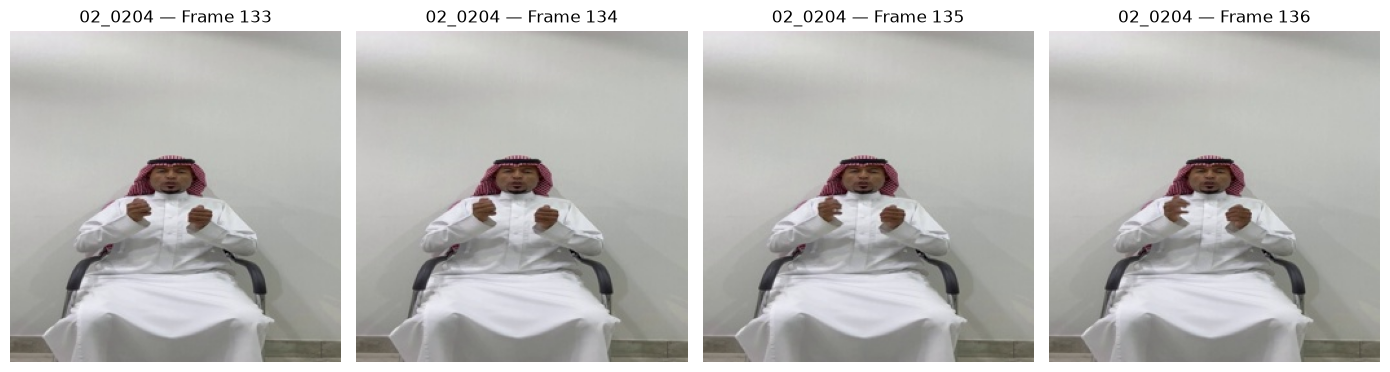

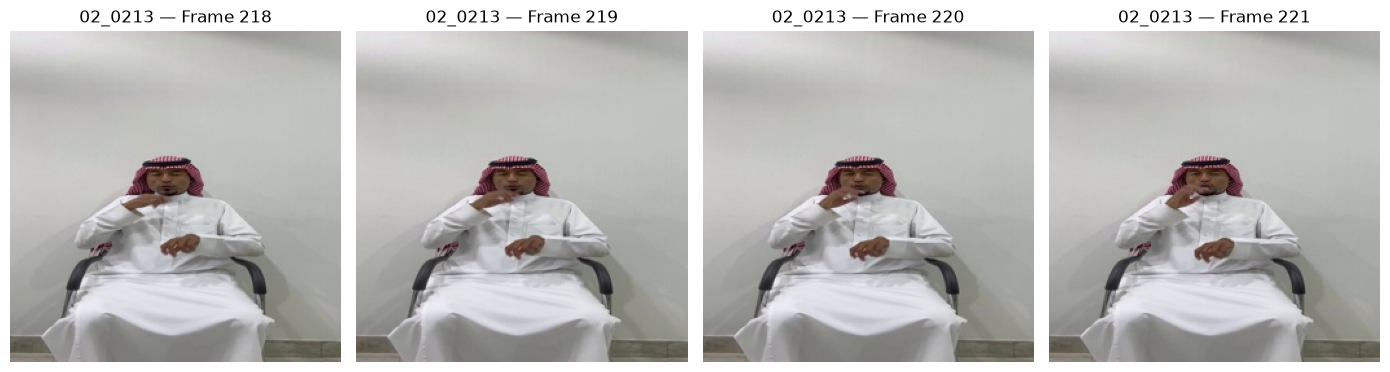

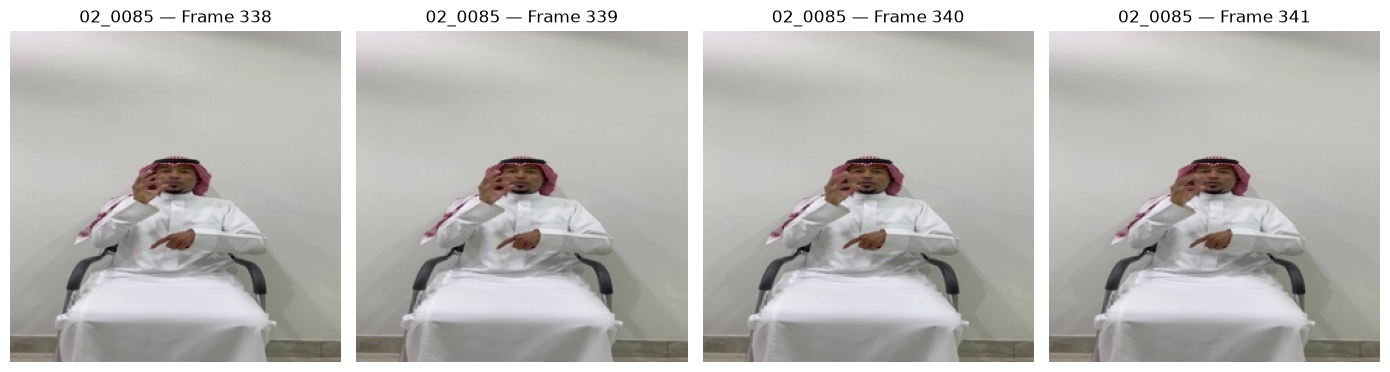

In [ ]:
review_cases = [
    ("02_0204", 134),
    ("02_0213", 219),
    ("02_0085", 339),
]
for sample_id, center_frame in review_cases:
    sample_directory = sample_directories[sample_id]
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    frame_indices = range(
        max(0, center_frame - 1),
        min(len(frame_paths), center_frame + 3),
    )
    fig, axes = plt.subplots(
        1,
        len(frame_indices),
        figsize=(14, 4),
    )
    for axis, frame_index in zip(axes, frame_indices):
        with Image.open(frame_paths[frame_index]) as frame_image:
            axis.imshow(frame_image)
        axis.set_title(f"{sample_id} — Frame {frame_index}")
        axis.axis("off")
    plt.tight_layout()
    plt.show()

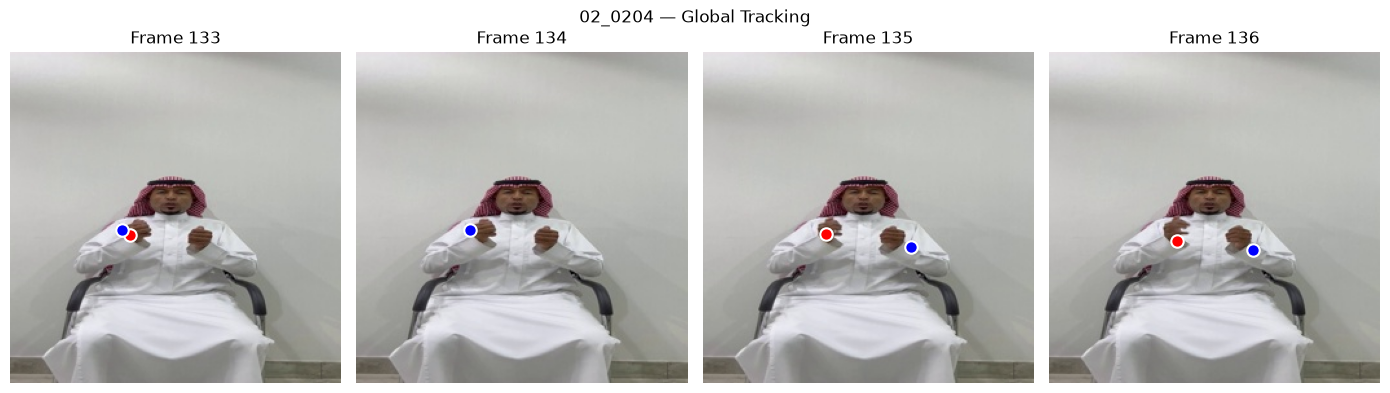

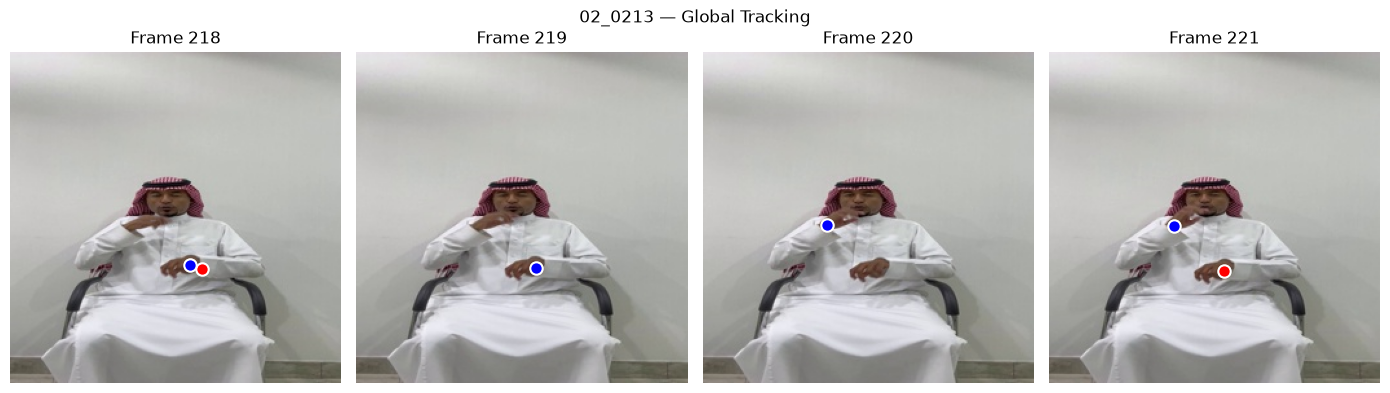

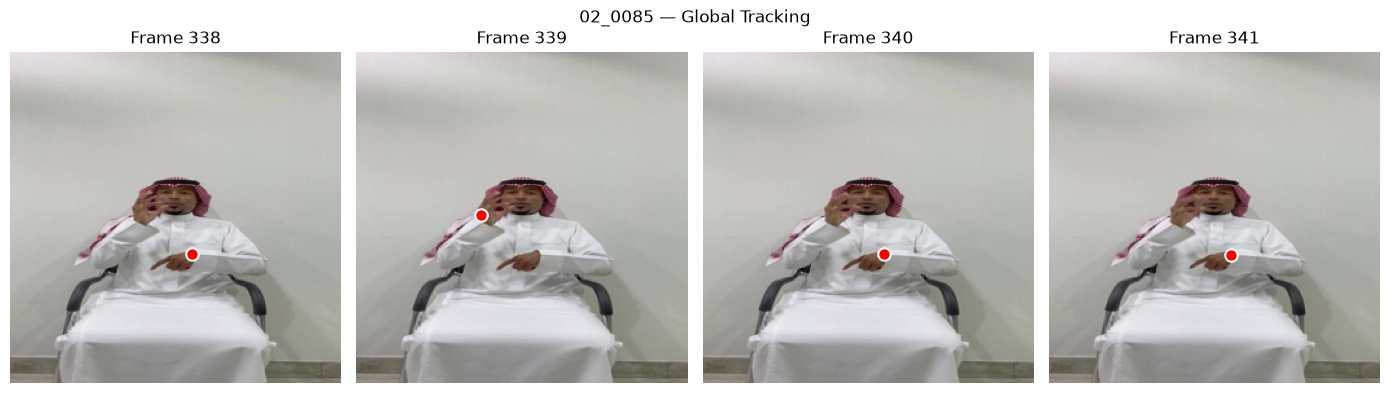

In [ ]:
review_cases = [
    ("02_0204", 134),
    ("02_0213", 219),
    ("02_0085", 339),
]
hand_colors = ("red", "blue")
for sample_id, center_frame in review_cases:
    keypoints = np.load(
        keypoints_directory / f"{sample_id}.npy",
        allow_pickle=False,
    )
    tracked = track_hand_slots_global(keypoints)
    frame_paths = sorted(sample_directories[sample_id].glob("*.jpg"))
    frame_indices = range(center_frame - 1, center_frame + 3)
    fig, axes = plt.subplots(1, 4, figsize=(14, 4))
    for axis, frame_index in zip(axes, frame_indices):
        with Image.open(frame_paths[frame_index]) as frame_image:
            axis.imshow(frame_image)
        for hand_index, color in enumerate(hand_colors):
            wrist = tracked[frame_index, hand_index, :2]
            if not np.isfinite(wrist).all():
                continue
            axis.scatter(
                wrist[0] * 256,
                wrist[1] * 256,
                color=color,
                s=80,
                edgecolors="white",
                linewidths=1.5,
            )
        axis.set_title(f"Frame {frame_index}")
        axis.axis("off")
    fig.suptitle(f"{sample_id} — Global Tracking")
    plt.tight_layout()
    plt.show()

In [ ]:
tracked_directory = (
    project
    / "data"
    / "processed"
    / "isharah500"
    / "hand_keypoints_tracked"
    / "dev"
)
tracked_directory.mkdir(parents=True, exist_ok=True)
for sample_path in sorted(keypoints_directory.glob("*.npy")):
    original = np.load(sample_path, allow_pickle=False)
    tracked = track_hand_slots_global(original)
    output_path = tracked_directory / sample_path.name
    np.save(output_path, tracked)
saved_files = list(tracked_directory.glob("*.npy"))
print("Saved tracked samples:", len(saved_files))
print("Output directory:", tracked_directory)

Saved tracked samples: 500
Output directory: e:\DEPI Project\SIGNOVA_ESL\data\processed\isharah500\hand_keypoints_tracked\dev


In [ ]:
tracking_module_path = project / "src" / "hand_tracking.py"
tracking_module_path.parent.mkdir(parents=True, exist_ok=True)
tracking_module_code = '''
"""Utilities for temporal hand-slot tracking."""
import numpy as np
def track_hand_slots(keypoints, max_distance=0.15, max_gap=15):
    """Match detected hands to slots using recent wrist positions."""
    hand_count = keypoints.shape[1]
    tracked = np.full_like(keypoints, np.nan)
    last_positions = np.full((hand_count, 2), np.nan)
    last_seen = np.full(hand_count, -1, dtype=int)
    for frame_index, frame in enumerate(keypoints):
        detected_slots = np.flatnonzero(
            np.isfinite(frame[:, :2]).all(axis=1)
        )
        detections = frame[detected_slots]
        if len(detections) == 0:
            continue
        candidates = []
        for detection_index, detection in enumerate(detections):
            for slot in range(hand_count):
                gap = frame_index - last_seen[slot]
                if not 0 < gap <= max_gap:
                    continue
                distance = np.linalg.norm(
                    detection[:2] - last_positions[slot]
                )
                if distance <= max_distance:
                    candidates.append(
                        (distance, detection_index, slot)
                    )
        matched_detections = set()
        matched_slots = set()
        for _, detection_index, slot in sorted(candidates):
            if (
                detection_index in matched_detections
                or slot in matched_slots
            ):
                continue
            tracked[frame_index, slot] = detections[detection_index]
            matched_detections.add(detection_index)
            matched_slots.add(slot)
        for detection_index, detection in enumerate(detections):
            if detection_index in matched_detections:
                continue
            free_slots = [
                slot
                for slot in range(hand_count)
                if slot not in matched_slots
            ]
            preferred_slot = int(detected_slots[detection_index])
            if preferred_slot in free_slots:
                assigned_slot = preferred_slot
            else:
                assigned_slot = free_slots[0]
            tracked[frame_index, assigned_slot] = detection
            matched_slots.add(assigned_slot)
        for slot in matched_slots:
            last_positions[slot] = tracked[frame_index, slot, :2]
            last_seen[slot] = frame_index
    return tracked
'''
tracking_module_path.write_text(
    tracking_module_code.strip() + "\n",
    encoding="utf-8",
)
print("Created:", tracking_module_path)

Created: e:\DEPI Project\SIGNOVA_ESL\src\hand_tracking.py


In [ ]:
source_directory = str(project / "src")
if source_directory not in sys.path:
    sys.path.insert(0, source_directory)
from hand_tracking import track_hand_slots as track_hand_slots_module
test_sample_ids = ["02_0001", "02_0010", "02_0425"]
for sample_id in test_sample_ids:
    sample_path = keypoints_directory / f"{sample_id}.npy"
    keypoints = np.load(sample_path, allow_pickle=False)
    notebook_result = track_hand_slots_global(keypoints)
    module_result = track_hand_slots_module(keypoints)
    np.testing.assert_array_equal(
        notebook_result,
        module_result,
        err_msg=f"Tracking mismatch for {sample_id}",
    )
    print(f"{sample_id}: PASS")
print("\nAll tracking module tests passed.")

02_0001: PASS
02_0010: PASS
02_0425: PASS

All tracking module tests passed.


In [ ]:
batch_script_path = project / "src" / "batch_tracking.py"
batch_script_code = '''
"""Batch processing for hand-keypoint tracking."""
import argparse
from pathlib import Path
import numpy as np
from hand_tracking import track_hand_slots
def process_directory(input_directory, output_directory):
    """Track all keypoint files and skip existing outputs."""
    input_directory = Path(input_directory)
    output_directory = Path(output_directory)
    if not input_directory.is_dir():
        raise FileNotFoundError(
            f"Input directory does not exist: {input_directory}"
        )
    if input_directory.resolve() == output_directory.resolve():
        raise ValueError(
            "Input and output directories must be different."
        )
    output_directory.mkdir(parents=True, exist_ok=True)
    processed_count = 0
    skipped_count = 0
    for input_path in sorted(input_directory.glob("*.npy")):
        output_path = output_directory / input_path.name
        if output_path.exists():
            skipped_count += 1
            continue
        keypoints = np.load(input_path, allow_pickle=False)
        tracked = track_hand_slots(keypoints)
        np.save(output_path, tracked)
        processed_count += 1
    print(f"Processed: {processed_count}")
    print(f"Skipped: {skipped_count}")
def main():
    """Parse command-line arguments and run tracking."""
    parser = argparse.ArgumentParser(
        description="Apply temporal tracking to hand keypoints."
    )
    parser.add_argument("--input", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    arguments = parser.parse_args()
    process_directory(arguments.input, arguments.output)
if __name__ == "__main__":
    main()
'''
batch_script_path.write_text(
    batch_script_code.strip() + "\n",
    encoding="utf-8",
)
print("Created:", batch_script_path)

Created: e:\DEPI Project\SIGNOVA_ESL\src\batch_tracking.py


In [ ]:
command = [
    sys.executable,
    str(project / "src" / "batch_tracking.py"),
    "--input",
    str(keypoints_directory),
    "--output",
    str(tracked_directory),
]
result = run(
    command,
    capture_output=True,
    text=True,
    check=False,
)
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)

Processed: 0
Skipped: 500



In [ ]:
model_path = project / "models" / "hand_landmarker.task"
assert model_path.is_file(), "MediaPipe model file is missing."
assert callable(extract_sample_hand_keypoints), (
    "Keypoint extraction function is not available."
)
print("MediaPipe model: READY")
print("Extraction function: READY")
print("Model size (MB):", round(model_path.stat().st_size / 1_000_000, 2))

MediaPipe model: READY
Extraction function: READY
Model size (MB): 7.82


In [ ]:
import inspect
print(
    inspect.getsource(extract_sample_hand_keypoints)
)

def extract_sample_hand_keypoints(sample_directory, model_path, fps=30):
    """Extract temporally ordered keypoints with consistent hand slots."""
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    if not frame_paths:
        raise ValueError(f"No JPG frames found in {sample_directory}")
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=HAND_COUNT,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
        min_tracking_confidence=0.3,
    )
    keypoint_sequences = []
    detection_counts = []
    with mp.tasks.vision.HandLandmarker.create_from_options(options) as landmarker:
        for frame_index, frame_path in enumerate(frame_paths):
            image = mp.Image.create_from_file(str(frame_path))
            timestamp_ms = round(frame_index * 1000 / fps)
           

In [ ]:
extraction_module_path = project / "src" / "hand_extraction.py"
extraction_module_code = '''
"""Extract hand landmarks from ordered video frames."""
from pathlib import Path
import mediapipe as mp
import numpy as np
HAND_COUNT = 2
LANDMARKS_PER_HAND = 21
COORDINATES_PER_LANDMARK = 3
HAND_FEATURE_COUNT = LANDMARKS_PER_HAND * COORDINATES_PER_LANDMARK
HAND_LABEL_TO_INDEX = {
    "Left": 0,
    "Right": 1,
}
def extract_sample_hand_keypoints(sample_directory, model_path, fps=30):
    """Extract ordered hand landmarks and per-frame detection counts."""
    sample_directory = Path(sample_directory)
    model_path = Path(model_path)
    if fps <= 0:
        raise ValueError("fps must be greater than zero.")
    if not model_path.is_file():
        raise FileNotFoundError(f"Model not found: {model_path}")
    frame_paths = sorted(sample_directory.glob("*.jpg"))
    if not frame_paths:
        raise ValueError(f"No JPG frames found in {sample_directory}")
    options = mp.tasks.vision.HandLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(
            model_asset_path=str(model_path)
        ),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_hands=HAND_COUNT,
        min_hand_detection_confidence=0.3,
        min_hand_presence_confidence=0.3,
        min_tracking_confidence=0.3,
    )
    keypoint_sequences = []
    detection_counts = []
    with mp.tasks.vision.HandLandmarker.create_from_options(
        options
    ) as landmarker:
        for frame_index, frame_path in enumerate(frame_paths):
            image = mp.Image.create_from_file(str(frame_path))
            timestamp_ms = round(frame_index * 1000 / fps)
            result = landmarker.detect_for_video(
                image,
                timestamp_ms,
            )
            frame_keypoints = np.full(
                (HAND_COUNT, HAND_FEATURE_COUNT),
                np.nan,
                dtype=np.float32,
            )
            for landmarks, handedness in zip(
                result.hand_landmarks,
                result.handedness,
            ):
                hand_label = handedness[0].category_name
                hand_index = HAND_LABEL_TO_INDEX.get(hand_label)
                if hand_index is None:
                    continue
                coordinates = [
                    coordinate
                    for landmark in landmarks
                    for coordinate in (
                        landmark.x,
                        landmark.y,
                        landmark.z,
                    )
                ]
                frame_keypoints[hand_index] = coordinates
            keypoint_sequences.append(frame_keypoints)
            detection_counts.append(len(result.hand_landmarks))
    return (
        np.stack(keypoint_sequences),
        np.asarray(detection_counts, dtype=np.int32),
    )
'''
extraction_module_path.write_text(
    extraction_module_code.strip() + "\n",
    encoding="utf-8",
)
print("Created:", extraction_module_path)

Created: e:\DEPI Project\SIGNOVA_ESL\src\hand_extraction.py


In [ ]:
from hand_extraction import (
    extract_sample_hand_keypoints as extract_from_module,
)
sample_id = "02_0001"
sample_directory = sample_directories[sample_id]
original_keypoints, original_counts = extract_sample_hand_keypoints(
    sample_directory,
    model_path,
)
module_keypoints, module_counts = extract_from_module(
    sample_directory,
    model_path,
)
np.testing.assert_allclose(
    original_keypoints,
    module_keypoints,
    rtol=0,
    atol=1e-6,
    equal_nan=True,
)
np.testing.assert_array_equal(
    original_counts,
    module_counts,
)
print("Extraction module: PASS")
print("Keypoints shape:", module_keypoints.shape)
print("Detection counts shape:", module_counts.shape)

Extraction module: PASS
Keypoints shape: (61, 2, 63)
Detection counts shape: (61,)


In [ ]:

parallel_script_path = project / "src" / "parallel_extraction.py"
parallel_script_code = '''
"""Extract hand keypoints from multiple samples in parallel."""
import argparse
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np

from hand_extraction import extract_sample_hand_keypoints


def process_sample(sample_directory, model_path, output_directory):
    """Extract one sample and save its keypoints."""
    output_path = output_directory / f"{sample_directory.name}.npy"

    if output_path.exists():
        return sample_directory.name, "skipped"

    keypoints, _ = extract_sample_hand_keypoints(
        sample_directory,
        model_path,
    )

    temporary_path = output_path.with_suffix(".tmp")

    try:
        with temporary_path.open("wb") as output_file:
            np.save(output_file, keypoints)

        os.replace(temporary_path, output_path)
    finally:
        temporary_path.unlink(missing_ok=True)

    return sample_directory.name, "processed"


def process_directory(
    input_directory,
    model_path,
    output_directory,
    workers=2,
    limit=None,
):
    """Process sample folders using separate worker processes."""
    if workers < 1:
        raise ValueError("workers must be at least 1.")

    if limit is not None and limit < 1:
        raise ValueError("limit must be at least 1.")

    input_directory = Path(input_directory)
    model_path = Path(model_path)
    output_directory = Path(output_directory)

    if not input_directory.is_dir():
        raise FileNotFoundError(input_directory)

    if not model_path.is_file():
        raise FileNotFoundError(model_path)

    sample_directories = sorted(
        directory
        for directory in input_directory.iterdir()
        if directory.is_dir()
        and any(directory.glob("*.jpg"))
    )

    if limit is not None:
        sample_directories = sample_directories[:limit]

    output_directory.mkdir(parents=True, exist_ok=True)

    pending_samples = [
        directory
        for directory in sample_directories
        if not (output_directory / f"{directory.name}.npy").exists()
    ]

    skipped_count = len(sample_directories) - len(pending_samples)
    processed_count = 0
    failed_samples = []

    with ProcessPoolExecutor(max_workers=workers) as executor:
        futures = {
            executor.submit(
                process_sample,
                directory,
                model_path,
                output_directory,
            ): directory.name
            for directory in pending_samples
        }

        for future in as_completed(futures):
            sample_id = futures[future]

            try:
                _, status = future.result()
                if status == "processed":
                    processed_count += 1
            except Exception as error:
                failed_samples.append((sample_id, str(error)))
                print(f"FAILED {sample_id}: {error}")

    print(f"Processed: {processed_count}")
    print(f"Skipped: {skipped_count}")
    print(f"Failed: {len(failed_samples)}")

    return failed_samples


def main():
    """Run extraction from the command line."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--input", type=Path, required=True)
    parser.add_argument("--model", type=Path, required=True)
    parser.add_argument("--output", type=Path, required=True)
    parser.add_argument("--workers", type=int, default=2)
    parser.add_argument("--limit", type=int)

    arguments = parser.parse_args()

    failures = process_directory(
        input_directory=arguments.input,
        model_path=arguments.model,
        output_directory=arguments.output,
        workers=arguments.workers,
        limit=arguments.limit,
    )

    if failures:
        raise SystemExit(1)


if __name__ == "__main__":
    main()
'''
parallel_script_path.write_text(
    parallel_script_code.strip() + "\n",
    encoding="utf-8",
)
print("Created:", parallel_script_path)

Created: e:\DEPI Project\SIGNOVA_ESL\src\parallel_extraction.py


In [ ]:
input_directory = sample_directories["02_0001"].parent
script_path = project / "src" / "parallel_extraction.py"
benchmark_results = {}
for worker_count in (1, 2):
    output_directory = (
        project
        / "data"
        / "processed"
        / "isharah500"
        / "benchmark"
        / f"workers_{worker_count}"
    )
    command = [
        sys.executable,
        str(script_path),
        "--input",
        str(input_directory),
        "--model",
        str(model_path),
        "--output",
        str(output_directory),
        "--workers",
        str(worker_count),
        "--limit",
        "5",
    ]
    start_time = perf_counter()
    result = run(
        command,
        capture_output=True,
        text=True,
        check=False,
    )
    elapsed_seconds = perf_counter() - start_time
    print(f"\nWorkers: {worker_count}")
    print(result.stdout)
    if result.returncode != 0:
        raise RuntimeError(result.stderr)
    benchmark_results[worker_count] = elapsed_seconds
    print(f"Time: {elapsed_seconds:.2f} seconds")
single_worker_time = benchmark_results[1]
parallel_time = benchmark_results[2]
print(
    f"\nSpeedup: {single_worker_time / parallel_time:.2f}x"
)


Workers: 1
Processed: 5
Skipped: 0
Failed: 0

Time: 38.91 seconds

Workers: 2
Processed: 5
Skipped: 0
Failed: 0

Time: 23.93 seconds

Speedup: 1.63x


In [ ]:
benchmark_root = (
    project / "data" / "processed" / "isharah500" / "benchmark"
)
sample_ids = sorted(sample_directories)[:5]
for worker_count in (1, 2):
    output_directory = benchmark_root / f"workers_{worker_count}"
    for sample_id in sample_ids:
        output_path = output_directory / f"{sample_id}.npy"
        assert output_path.is_file(), f"Missing: {output_path}"
        keypoints = np.load(output_path, allow_pickle=False)
        expected_shape = (
            frame_counts[sample_id],
            HAND_COUNT,
            HAND_FEATURE_COUNT,
        )
        assert keypoints.shape == expected_shape, sample_id
        assert keypoints.dtype == np.float32, sample_id
        assert np.all(np.isfinite(keypoints) | np.isnan(keypoints)), (
            sample_id
        )
    print(f"{worker_count} Worker(s): 5/5 files PASS")
print("Benchmark output validation: PASS")

1 Worker(s): 5/5 files PASS
2 Worker(s): 5/5 files PASS
Benchmark output validation: PASS


In [ ]:
benchmark_root = (
    project / "data" / "processed" / "isharah500" / "benchmark"
)
sample_ids = sorted(sample_directories)[:5]
for sample_id in sample_ids:
    single_worker_path = (
        benchmark_root / "workers_1" / f"{sample_id}.npy"
    )
    parallel_worker_path = (
        benchmark_root / "workers_2" / f"{sample_id}.npy"
    )
    single_worker_keypoints = np.load(
        single_worker_path,
        allow_pickle=False,
    )
    parallel_keypoints = np.load(
        parallel_worker_path,
        allow_pickle=False,
    )
    np.testing.assert_allclose(
        single_worker_keypoints,
        parallel_keypoints,
        rtol=0,
        atol=1e-6,
        equal_nan=True,
        err_msg=f"Mismatch in {sample_id}",
    )
    print(f"{sample_id}: PASS")
print("\nParallel extraction consistency: PASS")

02_0001: PASS
02_0002: PASS
02_0003: PASS
02_0004: PASS
02_0005: PASS

Parallel extraction consistency: PASS


In [ ]:
worker_count = 4
output_directory = (
    project
    / "data"
    / "processed"
    / "isharah500"
    / "benchmark"
    / "workers_4"
)
command = [
    sys.executable,
    str(project / "src" / "parallel_extraction.py"),
    "--input",
    str(sample_directories["02_0001"].parent),
    "--model",
    str(model_path),
    "--output",
    str(output_directory),
    "--workers",
    str(worker_count),
    "--limit",
    "5",
]
start_time = perf_counter()

result = run(
    command,
    capture_output=True,
    text=True,
    check=False,
)
elapsed_seconds = perf_counter() - start_time
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)
benchmark_results[worker_count] = elapsed_seconds
print(f"4 Workers Time: {elapsed_seconds:.2f} seconds")
print(f"Speedup: {benchmark_results[1] / elapsed_seconds:.2f}x")

Processed: 5
Skipped: 0
Failed: 0

4 Workers Time: 13.54 seconds
Speedup: 2.87x


In [ ]:
benchmark_root = (
    project / "data" / "processed" / "isharah500" / "benchmark"
)
sample_ids = sorted(sample_directories)[:5]
for sample_id in sample_ids:
    reference_path = (
        benchmark_root / "workers_1" / f"{sample_id}.npy"
    )
    parallel_path = (
        benchmark_root / "workers_4" / f"{sample_id}.npy"
    )
    reference = np.load(reference_path, allow_pickle=False)
    parallel = np.load(parallel_path, allow_pickle=False)
    np.testing.assert_allclose(
        reference,
        parallel,
        rtol=0,
        atol=1e-6,
        equal_nan=True,
        err_msg=f"Mismatch in {sample_id}",
    )
    print(f"{sample_id}: PASS")
print("\n4 Workers consistency: PASS")

02_0001: PASS
02_0002: PASS
02_0003: PASS
02_0004: PASS
02_0005: PASS

4 Workers consistency: PASS


In [ ]:
original_paths = sorted(keypoints_directory.glob("*.npy"))
tracked_paths = sorted(tracked_directory.glob("*.npy"))
assert len(original_paths) == 500
assert {path.name for path in original_paths} == {
    path.name for path in tracked_paths
}
for original_path in original_paths:
    tracked_path = tracked_directory / original_path.name
    original = np.load(original_path, allow_pickle=False)
    tracked = np.load(tracked_path, allow_pickle=False)
    assert original.shape == tracked.shape
    assert original.dtype == tracked.dtype == np.float32
    assert np.all(np.isfinite(tracked) | np.isnan(tracked))
    original_hand_counts = np.isfinite(
        original[:, :, :2]
    ).all(axis=2).sum(axis=1)
    tracked_hand_counts = np.isfinite(
        tracked[:, :, :2]
    ).all(axis=2).sum(axis=1)
    np.testing.assert_array_equal(
        original_hand_counts,
        tracked_hand_counts,
        err_msg=f"Detection count changed: {original_path.name}",
    )
print("Validated samples:", len(original_paths))
print("Tracking preserves per-frame hand counts: PASS")
print("Tracked dataset validation: PASS")

Validated samples: 500
Tracking preserves per-frame hand counts: PASS
Tracked dataset validation: PASS


In [ ]:
pipeline_path = project / "src" / "hand_pipeline.py"
pipeline_code = '''
"""Parallel hand-keypoint extraction and experimental tracking."""

import argparse
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
from pathlib import Path

import numpy as np

from hand_extraction import extract_sample_hand_keypoints
from hand_tracking import track_hand_slots


def save_array_atomic(output_path, array):
    """Save an array without leaving a partial final file."""
    temporary_path = output_path.with_suffix(".tmp")

    try:
        with temporary_path.open("wb") as output_file:
            np.save(output_file, array)

        os.replace(temporary_path, output_path)
    finally:
        temporary_path.unlink(missing_ok=True)


def process_sample(sample_directory, model_path, raw_dir, tracked_dir):
    """Extract and track one sample, reusing completed outputs."""
    sample_id = sample_directory.name
    raw_path = raw_dir / f"{sample_id}.npy"
    tracked_path = tracked_dir / f"{sample_id}.npy"

    if raw_path.exists() and tracked_path.exists():
        return sample_id, "skipped"

    if raw_path.exists():
        keypoints = np.load(raw_path, allow_pickle=False)
    else:
        keypoints, _ = extract_sample_hand_keypoints(
            sample_directory,
            model_path,
        )
        save_array_atomic(raw_path, keypoints)

    if not tracked_path.exists():
        tracked = track_hand_slots(keypoints)
        save_array_atomic(tracked_path, tracked)

    return sample_id, "processed"


def process_directory(
    input_directory,
    model_path,
    raw_dir,
    tracked_dir,
    workers=4,
    limit=None,
):
    """Process frame directories with resumable parallel workers."""
    input_directory = Path(input_directory)
    model_path = Path(model_path)
    raw_dir = Path(raw_dir)
    tracked_dir = Path(tracked_dir)

    if workers < 1:
        raise ValueError("workers must be at least 1.")

    if limit is not None and limit < 1:
        raise ValueError("limit must be at least 1.")

    if not input_directory.is_dir():
        raise FileNotFoundError(input_directory)

    if not model_path.is_file():
        raise FileNotFoundError(model_path)

    if raw_dir.resolve() == tracked_dir.resolve():
        raise ValueError("Raw and tracked directories must differ.")

    sample_directories = sorted(
        directory
        for directory in input_directory.iterdir()
        if directory.is_dir() and any(directory.glob("*.jpg"))
    )

    if limit is not None:
        sample_directories = sample_directories[:limit]

    raw_dir.mkdir(parents=True, exist_ok=True)
    tracked_dir.mkdir(parents=True, exist_ok=True)

    pending = [
        directory
        for directory in sample_directories
        if not (
            (raw_dir / f"{directory.name}.npy").exists()
            and (tracked_dir / f"{directory.name}.npy").exists()
        )
    ]

    processed_count = 0
    failed_count = 0

    with ProcessPoolExecutor(max_workers=workers) as executor:
        futures = [
            executor.submit(
                process_sample,
                directory,
                model_path,
                raw_dir,
                tracked_dir,
            )
            for directory in pending
        ]

        for future in as_completed(futures):
            try:
                future.result()
                processed_count += 1
            except Exception as error:
                failed_count += 1
                print(f"FAILED: {error}")

    print(f"Processed: {processed_count}")
    print(f"Skipped: {len(sample_directories) - len(pending)}")
    print(f"Failed: {failed_count}")

    return failed_count


def main():
    """Run the pipeline from the command line."""
    parser = argparse.ArgumentParser()
    parser.add_argument("--input", type=Path, required=True)
    parser.add_argument("--model", type=Path, required=True)
    parser.add_argument("--raw-output", type=Path, required=True)
    parser.add_argument("--tracked-output", type=Path, required=True)
    parser.add_argument("--workers", type=int, default=4)
    parser.add_argument("--limit", type=int)

    arguments = parser.parse_args()

    failed_count = process_directory(
        input_directory=arguments.input,
        model_path=arguments.model,
        raw_dir=arguments.raw_output,
        tracked_dir=arguments.tracked_output,
        workers=arguments.workers,
        limit=arguments.limit,
    )

    if failed_count:
        raise SystemExit(1)


if __name__ == "__main__":
    main()
'''
pipeline_path.write_text(
    pipeline_code.strip() + "\n",
    encoding="utf-8",
)
print("Created:", pipeline_path)

Created: e:\DEPI Project\SIGNOVA_ESL\src\hand_pipeline.py


In [ ]:
test_directory = (
    project / "data" / "processed" / "isharah500" / "pipeline_test"
)
raw_test_directory = test_directory / "raw"
tracked_test_directory = test_directory / "tracked"
command = [
    sys.executable,
    str(project / "src" / "hand_pipeline.py"),
    "--input",
    str(sample_directories["02_0001"].parent),
    "--model",
    str(model_path),
    "--raw-output",
    str(raw_test_directory),
    "--tracked-output",
    str(tracked_test_directory),
    "--workers",
    "3",
    "--limit",
    "3",
]
start_time = perf_counter()
result = run(
    command,
    capture_output=True,
    text=True,
    check=False,
)
elapsed_seconds = perf_counter() - start_time
print(result.stdout)
print(f"Execution time: {elapsed_seconds:.2f} seconds")
if result.returncode != 0:
    raise RuntimeError(result.stderr)

Processed: 3
Skipped: 0
Failed: 0

Execution time: 16.69 seconds


In [ ]:
test_sample_ids = sorted(sample_directories)[:3]
for sample_id in test_sample_ids:
    raw_path = raw_test_directory / f"{sample_id}.npy"
    tracked_path = tracked_test_directory / f"{sample_id}.npy"
    reference_path = keypoints_directory / f"{sample_id}.npy"
    assert raw_path.is_file(), f"Missing raw file: {sample_id}"
    assert tracked_path.is_file(), f"Missing tracked file: {sample_id}"
    raw_keypoints = np.load(raw_path, allow_pickle=False)
    tracked_keypoints = np.load(tracked_path, allow_pickle=False)
    reference_keypoints = np.load(reference_path, allow_pickle=False)
    expected_shape = (
        frame_counts[sample_id],
        HAND_COUNT,
        HAND_FEATURE_COUNT,
    )
    assert raw_keypoints.shape == expected_shape
    assert tracked_keypoints.shape == expected_shape
    np.testing.assert_allclose(
        raw_keypoints,
        reference_keypoints,
        rtol=0,
        atol=1e-6,
        equal_nan=True,
        err_msg=f"Extraction mismatch: {sample_id}",
    )
    expected_tracked = track_hand_slots_global(raw_keypoints)
    np.testing.assert_array_equal(
        tracked_keypoints,
        expected_tracked,
        err_msg=f"Tracking mismatch: {sample_id}",
    )
    print(f"{sample_id}: PASS")
print("\nUnified pipeline validation: PASS")

02_0001: PASS
02_0002: PASS
02_0003: PASS

Unified pipeline validation: PASS


In [ ]:
start_time = perf_counter()
result = run(
    command,
    capture_output=True,
    text=True,
    check=False,
)
elapsed_seconds = perf_counter() - start_time
print(result.stdout)
print(f"Execution time: {elapsed_seconds:.2f} seconds")
if result.returncode != 0:
    raise RuntimeError(result.stderr)
assert "Processed: 0" in result.stdout
assert "Skipped: 3" in result.stdout
assert "Failed: 0" in result.stdout
print("Resume test: PASS")

Processed: 0
Skipped: 3
Failed: 0

Execution time: 1.62 seconds
Resume test: PASS


In [ ]:
recovery_directory = test_directory / "recovery"
recovery_raw_directory = recovery_directory / "raw"
recovery_tracked_directory = recovery_directory / "tracked"
recovery_raw_directory.mkdir(parents=True, exist_ok=True)
recovery_tracked_directory.mkdir(parents=True, exist_ok=True)
sample_id = "02_0001"
source_raw_path = raw_test_directory / f"{sample_id}.npy"
recovery_raw_path = recovery_raw_directory / f"{sample_id}.npy"
# Reuse existing keypoints without running MediaPipe again.
raw_keypoints = np.load(source_raw_path, allow_pickle=False)
np.save(recovery_raw_path, raw_keypoints)
recovery_command = [
    sys.executable,
    str(project / "src" / "hand_pipeline.py"),
    "--input",
    str(sample_directories[sample_id].parent),
    "--model",
    str(model_path),
    "--raw-output",
    str(recovery_raw_directory),
    "--tracked-output",
    str(recovery_tracked_directory),
    "--workers",
    "1",
    "--limit",
    "1",
]
result = run(
    recovery_command,
    capture_output=True,
    text=True,
    check=False,
)
print(result.stdout)
if result.returncode != 0:
    raise RuntimeError(result.stderr)
assert "Processed: 1" in result.stdout
assert "Failed: 0" in result.stdout
recovered_path = recovery_tracked_directory / f"{sample_id}.npy"
assert recovered_path.is_file()
recovered = np.load(recovered_path, allow_pickle=False)
expected = track_hand_slots_global(raw_keypoints)
np.testing.assert_array_equal(recovered, expected)
print("Missing tracked output recovery: PASS")

Processed: 1
Skipped: 0
Failed: 0

Missing tracked output recovery: PASS


In [ ]:
test_file_path = project / "tests" / "test_hand_tracking.py"
test_file_path.parent.mkdir(parents=True, exist_ok=True)

test_code = '''
"""Unit tests for experimental hand-slot tracking."""

import sys
from pathlib import Path

import numpy as np
import pytest


SOURCE_DIRECTORY = Path(__file__).resolve().parents[1] / "src"
sys.path.insert(0, str(SOURCE_DIRECTORY))

from hand_tracking import track_hand_slots


def make_keypoints(frame_count=3):
    """Create a small, valid hand-keypoint sequence."""
    keypoints = np.full(
        (frame_count, 2, 63),
        np.nan,
        dtype=np.float32,
    )

    keypoints[:, 0, :3] = [0.2, 0.3, 0.0]
    keypoints[:, 1, :3] = [0.7, 0.3, 0.0]

    return keypoints


def test_tracking_preserves_shape_and_dtype():
    """Tracking should preserve array structure."""
    original = make_keypoints()

    tracked = track_hand_slots(original)

    assert tracked.shape == original.shape
    assert tracked.dtype == original.dtype


def test_tracking_preserves_detection_counts():
    """Tracking should retain the number of detected hands."""
    original = make_keypoints()
    original[1, 1] = np.nan

    tracked = track_hand_slots(original)

    original_counts = np.isfinite(
        original[:, :, :2]
    ).all(axis=2).sum(axis=1)

    tracked_counts = np.isfinite(
        tracked[:, :, :2]
    ).all(axis=2).sum(axis=1)

    np.testing.assert_array_equal(
        original_counts,
        tracked_counts,
    )


def test_tracking_preserves_valid_coordinates():
    """Tracking should not modify landmark values."""
    original = make_keypoints()
    original[1, 1] = np.nan

    tracked = track_hand_slots(original)

    original_values = np.sort(original[np.isfinite(original)])
    tracked_values = np.sort(tracked[np.isfinite(tracked)])

    np.testing.assert_array_equal(
        original_values,
        tracked_values,
    )
'''

test_file_path.write_text(
    test_code.strip() + "\n",
    encoding="utf-8",
)

print("Created:", test_file_path)


Created: e:\DEPI Project\SIGNOVA_ESL\tests\test_hand_tracking.py


In [ ]:
test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(project / "tests" / "test_hand_tracking.py"),
    "-v",
]

result = run(
    test_command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Unit tests failed.")

print("Hand tracking unit tests: PASS")


============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-9.1.1, pluggy-1.6.0 -- e:\DEPI Project\SIGNOVA_ESL\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: e:\DEPI Project\SIGNOVA_ESL
plugins: anyio-4.15.1, platformdirs-4.13.0
collecting ... collected 3 items

tests/test_hand_tracking.py::test_tracking_preserves_shape_and_dtype PASSED [ 33%]
tests/test_hand_tracking.py::test_tracking_preserves_detection_counts PASSED [ 66%]
tests/test_hand_tracking.py::test_tracking_preserves_valid_coordinates PASSED [100%]

============================== 3 passed in 0.19s ==============================

Hand tracking unit tests: PASS


In [ ]:
validation_module_path = project / "src" / "keypoint_validation.py"

validation_module_code = '''
"""Validate saved hand-keypoint arrays."""

from pathlib import Path

import numpy as np


HAND_COUNT = 2
HAND_FEATURE_COUNT = 63


def is_valid_keypoint_file(file_path, expected_frames=None):
    """Check whether a saved keypoint file is structurally valid."""
    file_path = Path(file_path)

    if not file_path.is_file():
        return False

    try:
        keypoints = np.load(file_path, allow_pickle=False)
    except (OSError, ValueError, EOFError):
        return False

    if keypoints.ndim != 3:
        return False

    if keypoints.shape[0] == 0:
        return False

    if keypoints.shape[1:] != (HAND_COUNT, HAND_FEATURE_COUNT):
        return False

    if keypoints.dtype != np.float32:
        return False

    if expected_frames is not None:
        if keypoints.shape[0] != expected_frames:
            return False

    return bool(
        np.all(np.isfinite(keypoints) | np.isnan(keypoints))
    )
'''

validation_module_path.write_text(
    validation_module_code.strip() + "\n",
    encoding="utf-8",
)

print("Created:", validation_module_path)


Created: e:\DEPI Project\SIGNOVA_ESL\src\keypoint_validation.py


In [ ]:
validation_test_path = (
    project / "tests" / "test_keypoint_validation.py"
)

validation_test_code = '''
"""Unit tests for saved keypoint validation."""

import sys
from pathlib import Path

import numpy as np
import pytest


SOURCE_DIRECTORY = Path(__file__).resolve().parents[1] / "src"
sys.path.insert(0, str(SOURCE_DIRECTORY))

from keypoint_validation import is_valid_keypoint_file


def test_valid_keypoint_file(tmp_path):
    """Accept a correctly formatted keypoint array."""
    file_path = tmp_path / "valid.npy"
    keypoints = np.full((10, 2, 63), np.nan, dtype=np.float32)
    np.save(file_path, keypoints)

    assert is_valid_keypoint_file(file_path, expected_frames=10)


def test_missing_keypoint_file(tmp_path):
    """Reject files that do not exist."""
    assert not is_valid_keypoint_file(tmp_path / "missing.npy")


def test_corrupted_keypoint_file(tmp_path):
    """Reject unreadable NumPy files."""
    file_path = tmp_path / "corrupted.npy"
    file_path.write_bytes(b"invalid numpy data")

    assert not is_valid_keypoint_file(file_path)


def test_invalid_shape(tmp_path):
    """Reject arrays with unexpected dimensions."""
    file_path = tmp_path / "invalid_shape.npy"
    np.save(file_path, np.zeros((10, 63), dtype=np.float32))

    assert not is_valid_keypoint_file(file_path)


def test_invalid_dtype(tmp_path):
    """Reject arrays with unexpected data types."""
    file_path = tmp_path / "invalid_dtype.npy"
    np.save(file_path, np.zeros((10, 2, 63), dtype=np.float64))

    assert not is_valid_keypoint_file(file_path)


def test_invalid_frame_count(tmp_path):
    """Reject arrays with an unexpected frame count."""
    file_path = tmp_path / "invalid_frames.npy"
    np.save(file_path, np.zeros((10, 2, 63), dtype=np.float32))

    assert not is_valid_keypoint_file(file_path, expected_frames=20)


def test_infinite_values(tmp_path):
    """Reject arrays containing infinite coordinates."""
    file_path = tmp_path / "infinite.npy"
    keypoints = np.zeros((10, 2, 63), dtype=np.float32)
    keypoints[0, 0, 0] = np.inf
    np.save(file_path, keypoints)

    assert not is_valid_keypoint_file(file_path)
'''

validation_test_path.write_text(
    validation_test_code.strip() + "\n",
    encoding="utf-8",
)

print("Created:", validation_test_path)


Created: e:\DEPI Project\SIGNOVA_ESL\tests\test_keypoint_validation.py


In [ ]:
test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(project / "tests"),
    "-v",
    "--color=no",
]

result = run(
    test_command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Unit tests failed.")

print("All unit tests: PASS")


============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-9.1.1, pluggy-1.6.0 -- e:\DEPI Project\SIGNOVA_ESL\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: e:\DEPI Project\SIGNOVA_ESL
plugins: anyio-4.15.1, platformdirs-4.13.0
collecting ... collected 10 items

tests/test_hand_tracking.py::test_tracking_preserves_shape_and_dtype PASSED [ 10%]
tests/test_hand_tracking.py::test_tracking_preserves_detection_counts PASSED [ 20%]
tests/test_hand_tracking.py::test_tracking_preserves_valid_coordinates PASSED [ 30%]
tests/test_keypoint_validation.py::test_valid_keypoint_file PASSED       [ 40%]
tests/test_keypoint_validation.py::test_missing_keypoint_file PASSED     [ 50%]
tests/test_keypoint_validation.py::test_corrupted_keypoint_file PASSED   [ 60%]
tests/test_keypoint_validation.py::test_invalid_shape PASSED             [ 70%]
tests/test_keypoint_validation.py::test_invalid_dtype PASSED             [ 80%]
tests/test_k

In [ ]:
pipeline_path = project / "src" / "hand_pipeline.py"
pipeline_source = pipeline_path.read_text(encoding="utf-8")

backup_path = pipeline_path.with_suffix(".py.bak")
backup_path.write_text(pipeline_source, encoding="utf-8")

old_import = "from hand_tracking import track_hand_slots"
new_import = (
    "from hand_tracking import track_hand_slots\n"
    "from keypoint_validation import is_valid_keypoint_file"
)

old_function = '''    if raw_path.exists() and tracked_path.exists():
        return sample_id, "skipped"

    if raw_path.exists():
        keypoints = np.load(raw_path, allow_pickle=False)
    else:
        keypoints, _ = extract_sample_hand_keypoints(
            sample_directory,
            model_path,
        )
        save_array_atomic(raw_path, keypoints)

    if not tracked_path.exists():
        tracked = track_hand_slots(keypoints)
        save_array_atomic(tracked_path, tracked)

    return sample_id, "processed"'''

new_function = '''    expected_frames = sum(
        1 for _ in sample_directory.glob("*.jpg")
    )

    raw_valid = is_valid_keypoint_file(
        raw_path,
        expected_frames=expected_frames,
    )
    tracked_valid = is_valid_keypoint_file(
        tracked_path,
        expected_frames=expected_frames,
    )

    if raw_valid and tracked_valid:
        return sample_id, "skipped"

    if raw_valid:
        keypoints = np.load(raw_path, allow_pickle=False)
    else:
        keypoints, _ = extract_sample_hand_keypoints(
            sample_directory,
            model_path,
        )
        save_array_atomic(raw_path, keypoints)

    tracked = track_hand_slots(keypoints)
    save_array_atomic(tracked_path, tracked)

    return sample_id, "processed"'''

old_pending = '''        if not (
            (raw_dir / f"{directory.name}.npy").exists()
            and (tracked_dir / f"{directory.name}.npy").exists()
        )'''

new_pending = '''        if not (
            is_valid_keypoint_file(
                raw_dir / f"{directory.name}.npy",
                expected_frames=sum(1 for _ in directory.glob("*.jpg")),
            )
            and is_valid_keypoint_file(
                tracked_dir / f"{directory.name}.npy",
                expected_frames=sum(1 for _ in directory.glob("*.jpg")),
            )
        )'''

replacements = [
    (old_import, new_import),
    (old_function, new_function),
    (old_pending, new_pending),
]

for old_text, new_text in replacements:
    if pipeline_source.count(old_text) != 1:
        raise ValueError(
            "Expected pipeline code was not found exactly once. "
            "No changes were saved."
        )

    pipeline_source = pipeline_source.replace(old_text, new_text, 1)

pipeline_path.write_text(pipeline_source, encoding="utf-8")

print("Updated:", pipeline_path)
print("Backup:", backup_path)


Updated: e:\DEPI Project\SIGNOVA_ESL\src\hand_pipeline.py
Backup: e:\DEPI Project\SIGNOVA_ESL\src\hand_pipeline.py.bak


In [ ]:
result = run(
    command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Updated pipeline failed.")

assert "Processed: 0" in result.stdout
assert "Skipped: 3" in result.stdout
assert "Failed: 0" in result.stdout

print("Safe resume validation: PASS")


Processed: 0
Skipped: 3
Failed: 0

Safe resume validation: PASS


In [ ]:
corruption_test_directory = test_directory / "corruption_test"
corruption_raw_directory = corruption_test_directory / "raw"
corruption_tracked_directory = corruption_test_directory / "tracked"

corruption_raw_directory.mkdir(parents=True, exist_ok=True)
corruption_tracked_directory.mkdir(parents=True, exist_ok=True)

sample_id = "02_0001"
file_name = f"{sample_id}.npy"

# Prepare a valid raw file in the isolated test directory.
reference_raw = np.load(
    raw_test_directory / file_name,
    allow_pickle=False,
)

np.save(corruption_raw_directory / file_name, reference_raw)

# Simulate a corrupted tracked output.
corrupted_path = corruption_tracked_directory / file_name
corrupted_path.write_bytes(b"corrupted numpy file")

assert not is_valid_keypoint_file(
    corrupted_path,
    expected_frames=frame_counts[sample_id],
)

corruption_command = [
    sys.executable,
    str(project / "src" / "hand_pipeline.py"),
    "--input",
    str(sample_directories[sample_id].parent),
    "--model",
    str(model_path),
    "--raw-output",
    str(corruption_raw_directory),
    "--tracked-output",
    str(corruption_tracked_directory),
    "--workers",
    "1",
    "--limit",
    "1",
]

result = run(
    corruption_command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

assert "Processed: 1" in result.stdout
assert "Failed: 0" in result.stdout

assert is_valid_keypoint_file(
    corrupted_path,
    expected_frames=frame_counts[sample_id],
)

recovered = np.load(corrupted_path, allow_pickle=False)
expected = track_hand_slots_global(reference_raw)

np.testing.assert_array_equal(recovered, expected)

print("Corrupted tracked file recovery: PASS")


Processed: 1
Skipped: 0
Failed: 0

Corrupted tracked file recovery: PASS


In [ ]:
raw_recovery_directory = test_directory / "raw_recovery"
raw_output_directory = raw_recovery_directory / "raw"
tracked_output_directory = raw_recovery_directory / "tracked"

raw_output_directory.mkdir(parents=True, exist_ok=True)
tracked_output_directory.mkdir(parents=True, exist_ok=True)

sample_id = "02_0001"
file_name = f"{sample_id}.npy"

corrupted_raw_path = raw_output_directory / file_name
tracked_output_path = tracked_output_directory / file_name

# Simulate a corrupted raw file.
corrupted_raw_path.write_bytes(b"corrupted raw keypoints")

# Keep a valid tracked file to test recovery behavior.
reference_tracked = np.load(
    tracked_test_directory / file_name,
    allow_pickle=False,
)
np.save(tracked_output_path, reference_tracked)

assert not is_valid_keypoint_file(corrupted_raw_path)

raw_recovery_command = [
    sys.executable,
    str(project / "src" / "hand_pipeline.py"),
    "--input",
    str(sample_directories[sample_id].parent),
    "--model",
    str(model_path),
    "--raw-output",
    str(raw_output_directory),
    "--tracked-output",
    str(tracked_output_directory),
    "--workers",
    "1",
    "--limit",
    "1",
]

result = run(
    raw_recovery_command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

assert "Processed: 1" in result.stdout
assert "Failed: 0" in result.stdout

assert is_valid_keypoint_file(
    corrupted_raw_path,
    expected_frames=frame_counts[sample_id],
)

recovered_raw = np.load(corrupted_raw_path, allow_pickle=False)
reference_raw = np.load(
    raw_test_directory / file_name,
    allow_pickle=False,
)

np.testing.assert_allclose(
    recovered_raw,
    reference_raw,
    rtol=0,
    atol=1e-6,
    equal_nan=True,
)

print("Corrupted raw file recovery: PASS")


Processed: 1
Skipped: 0
Failed: 0

Corrupted raw file recovery: PASS


In [ ]:
pipeline_test_path = project / "tests" / "test_hand_pipeline.py"

pipeline_test_code = '''
"""Tests for resumable hand-keypoint processing."""

import sys
from pathlib import Path
from unittest.mock import patch

import numpy as np


SOURCE_DIRECTORY = Path(__file__).resolve().parents[1] / "src"
sys.path.insert(0, str(SOURCE_DIRECTORY))

from hand_pipeline import process_sample
from keypoint_validation import is_valid_keypoint_file


def make_keypoints(frame_count=3):
    """Create a valid synthetic keypoint sequence."""
    return np.zeros((frame_count, 2, 63), dtype=np.float32)


def prepare_directories(tmp_path):
    """Create isolated directories and three placeholder frames."""
    sample_directory = tmp_path / "02_0001"
    raw_directory = tmp_path / "raw"
    tracked_directory = tmp_path / "tracked"

    sample_directory.mkdir()
    raw_directory.mkdir()
    tracked_directory.mkdir()

    for frame_index in range(3):
        (sample_directory / f"frame{frame_index:04d}.jpg").touch()

    return sample_directory, raw_directory, tracked_directory


def test_recovers_corrupted_tracked_file(tmp_path):
    """Rebuild tracked output without rerunning extraction."""
    sample_directory, raw_directory, tracked_directory = (
        prepare_directories(tmp_path)
    )

    keypoints = make_keypoints()
    np.save(raw_directory / "02_0001.npy", keypoints)

    tracked_path = tracked_directory / "02_0001.npy"
    tracked_path.write_bytes(b"corrupted")

    with patch(
        "hand_pipeline.extract_sample_hand_keypoints"
    ) as extraction_mock:
        sample_id, status = process_sample(
            sample_directory,
            tmp_path / "model.task",
            raw_directory,
            tracked_directory,
        )

    extraction_mock.assert_not_called()
    assert sample_id == "02_0001"
    assert status == "processed"
    assert is_valid_keypoint_file(tracked_path, expected_frames=3)


def test_recovers_corrupted_raw_file(tmp_path):
    """Rerun extraction when raw keypoints are corrupted."""
    sample_directory, raw_directory, tracked_directory = (
        prepare_directories(tmp_path)
    )

    raw_path = raw_directory / "02_0001.npy"
    raw_path.write_bytes(b"corrupted")

    np.save(
        tracked_directory / "02_0001.npy",
        make_keypoints(),
    )

    expected_keypoints = make_keypoints()
    detection_counts = np.full(3, 2, dtype=np.int32)

    with patch(
        "hand_pipeline.extract_sample_hand_keypoints",
        return_value=(expected_keypoints, detection_counts),
    ) as extraction_mock:
        sample_id, status = process_sample(
            sample_directory,
            tmp_path / "model.task",
            raw_directory,
            tracked_directory,
        )

    extraction_mock.assert_called_once()
    assert sample_id == "02_0001"
    assert status == "processed"
    assert is_valid_keypoint_file(raw_path, expected_frames=3)
    assert is_valid_keypoint_file(
        tracked_directory / "02_0001.npy",
        expected_frames=3,
    )
'''

pipeline_test_path.write_text(
    pipeline_test_code.strip() + "\n",
    encoding="utf-8",
)

print("Created:", pipeline_test_path)


Created: e:\DEPI Project\SIGNOVA_ESL\tests\test_hand_pipeline.py


In [ ]:
test_command = [
    sys.executable,
    "-m",
    "pytest",
    str(project / "tests"),
    "-v",
    "--color=no",
]

result = run(
    test_command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Test suite failed.")

print("Full test suite: PASS")


============================= test session starts =============================
platform win32 -- Python 3.13.15, pytest-9.1.1, pluggy-1.6.0 -- e:\DEPI Project\SIGNOVA_ESL\.venv\Scripts\python.exe
cachedir: .pytest_cache
rootdir: e:\DEPI Project\SIGNOVA_ESL
plugins: anyio-4.15.1, platformdirs-4.13.0
collecting ... collected 12 items

tests/test_hand_pipeline.py::test_recovers_corrupted_tracked_file PASSED [  8%]
tests/test_hand_pipeline.py::test_recovers_corrupted_raw_file PASSED     [ 16%]
tests/test_hand_tracking.py::test_tracking_preserves_shape_and_dtype PASSED [ 25%]
tests/test_hand_tracking.py::test_tracking_preserves_detection_counts PASSED [ 33%]
tests/test_hand_tracking.py::test_tracking_preserves_valid_coordinates PASSED [ 41%]
tests/test_keypoint_validation.py::test_valid_keypoint_file PASSED       [ 50%]
tests/test_keypoint_validation.py::test_missing_keypoint_file PASSED     [ 58%]
tests/test_keypoint_validation.py::test_corrupted_keypoint_file PASSED   [ 66%]
tests/test_k

In [ ]:
source_files = sorted((project / "src").glob("*.py"))
test_files = sorted((project / "tests").glob("test_*.py"))

command = [
    sys.executable,
    "-m",
    "compileall",
    "-q",
    *[str(path) for path in source_files + test_files],
]

result = run(
    command,
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Python syntax check failed.")

print("Source files checked:", len(source_files))
print("Test files checked:", len(test_files))
print("Python syntax check: PASS")


Source files checked: 6
Test files checked: 3
Python syntax check: PASS


In [ ]:
readme_path = project / "README.md"

readme_content = """# SIGNOVA — Hand Keypoint Processing

## Overview

A reusable data-processing pipeline for extracting hand landmarks
from sign-language video frames using MediaPipe Tasks Vision.

The pipeline supports parallel processing, experimental temporal
hand tracking, output validation, and resumable execution.

## Project Structure

- `src/hand_extraction.py` — MediaPipe hand-landmark extraction.
- `src/hand_tracking.py` — Experimental hand-slot tracking.
- `src/hand_pipeline.py` — Parallel extraction and tracking.
- `src/parallel_extraction.py` — Parallel extraction only.
- `src/batch_tracking.py` — Batch tracking only.
- `src/keypoint_validation.py` — NumPy output validation.
- `tests/` — Automated unit tests.
- `notebooks/` — Data exploration and experiments.
- `models/hand_landmarker.task` — MediaPipe model.

## Requirements

- Python 3.13 (tested with 3.13.15)
- NumPy
- MediaPipe Tasks Vision
- pytest (for testing)

## Input Format

Each sample is a directory containing ordered JPG frames:

```text
videos/
    02_0001/
        frame0000.jpg
        frame0001.jpg
        ...
    02_0002/
        ...
```

## Run the Pipeline

Run from the project root:

```bash
python src/hand_pipeline.py \\
  --input "data/raw/isharah500/videos/02/02" \\
  --model "models/hand_landmarker.task" \\
  --raw-output "data/processed/isharah500/hand_keypoints/dev" \\
  --tracked-output "data/processed/isharah500/hand_keypoints_tracked/dev" \\
  --workers 4
```

The input directory must directly contain sample directories.

## Output

Each sample produces two NumPy arrays:

- Raw keypoints: `(frames, 2, 63)`
- Tracked keypoints: `(frames, 2, 63)`

Arrays use `float32`. Missing detections are represented by `NaN`.

## Resume and Recovery

The pipeline validates saved arrays before skipping them.

- Valid raw and tracked outputs: skip.
- Invalid or missing tracked output: rebuild from valid raw output.
- Invalid or missing raw output: rerun extraction and tracking.

Outputs are saved using temporary files and atomic replacement.

## Tests

```bash
python -m pytest tests -v
```

Current test suite: 12 tests passed.

## Benchmark

Five sample videos on the development machine:

| Workers | Time |
| --- | ---: |
| 1 | 38.91 seconds |
| 2 | 23.93 seconds |
| 4 | 13.54 seconds |

Four workers achieved approximately 2.87x speedup in this test.
Performance may differ on larger workloads.

## Dataset Scope

Isharah-500 is a Saudi Sign Language dataset for
sentence-level continuous sign-language recognition.

The processed signer `02` belongs to the signer-independent
development split, not the training split.

Do not treat this dataset as Egyptian Sign Language or
mix it directly with isolated-sign datasets.

## Known Limitations

- Hand-slot tracking is experimental and can still swap identities.
- MediaPipe handedness may depend on image mirroring.
- Validation checks array structure, not semantic correctness.
- Timestamps assume 30 FPS; original recording FPS is unverified.
- Only the downloaded signer `02` has been processed and checked.
- The pipeline does not train a recognition model.
- Dataset usage must comply with its license and team approval.
"""

if readme_path.exists():
    print("README already exists; no changes made.")
else:
    readme_path.write_text(readme_content, encoding="utf-8")
    print("Created:", readme_path)


Created: e:\DEPI Project\SIGNOVA_ESL\README.md


In [ ]:
required_files = [
    "README.md",
    "src/hand_extraction.py",
    "src/hand_tracking.py",
    "src/hand_pipeline.py",
    "src/parallel_extraction.py",
    "src/batch_tracking.py",
    "src/keypoint_validation.py",
    "tests/test_hand_tracking.py",
    "tests/test_hand_pipeline.py",
    "tests/test_keypoint_validation.py",
    "models/hand_landmarker.task",
]

missing_files = [
    relative_path
    for relative_path in required_files
    if not (project / relative_path).is_file()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing project files: {missing_files}"
    )

result = run(
    [sys.executable, "-m", "pytest", "tests", "-q", "--color=no"],
    cwd=project,
    capture_output=True,
    text=True,
    check=False,
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Final tests failed.")

print("Required project files:", len(required_files))
print("Final delivery check: PASS")


............                                                             [100%]
12 passed in 0.89s

Required project files: 11
Final delivery check: PASS
